# MLP ordinal (CORN + Cross-Entropy ponderada) com embeddings — versão corrigida
**DAA 2026/2027 — previsão de `AGE_RANGE`**

Esta versão corrige os problemas encontrados na revisão do notebook `04_mlp_corn_cv5`:

| # | Problema | Correção |
|---|---|---|
| 1 | Discrepâncias comparadas com pessoas de outras idades | Cada caso é comparado com os "normais" **da mesma classe real** (secção 12.3) |
| 2 | Regressão para o centro: classes extremas marcadas como discrepantes | Desvio **ajustado por classe** (subtrai o desvio médio da classe) |
| 3 | Discrepâncias que são só incerteza | Critério exige desvio ajustado ≥ 3 **e** desvio-padrão ordinal ≤ 2.5; ordenação pelo desvio relativo à incerteza |
| 4 | F1 otimista (escolhas feitas nos mesmos folds) | **CV repetida com outras partições** + intervalo de confiança bootstrap (secção 8) |
| 5 | Variação grande entre folds | Reportada explicitamente (média ± dp, IC 95%) |
| 6 | Overfitting persistente | Regularização revista e comparada em 2 partições (secção 9) |
| 7 | F1 inflacionado pela estrutura do questionário | Dois modelos com papéis separados: **competição** (todas as variáveis) e **perfil** (sem saltos nem agregado) |
| 8 | Classes intermédias fracas | Analisado: F1 por classe + acerto a ±1 classe (limite dos dados, não um erro do modelo) |
| 9 | Probabilidades demasiado confiantes | 15 épocas em vez de 20 reduz o excesso de confiança (fica ~2–3 pontos nas faixas intermédias, ECE 0.021); a **calibração por temperatura** é ajustada de forma **cross-fitted** entre folds externos (secção 5) |
| – | Importância só no fold 0 | Média dos 5 folds + importância por **grupos** de variáveis correlacionadas |
| – | QuantileTransformer em colunas 0/1 | Binárias passam como 0/1 |
| – | Stacking | Exporta o nº do fold de cada linha; os outros modelos base têm de usar os mesmos folds |
| R2 | Modelo de perfil ainda via o salto do **módulo reprodutivo das mulheres** (NT2, IN20–IN28) e as **idades declaradas** | Detetor de saltos geral (qualquer classe, por sexo) + exclusão do módulo inteiro e das idades declaradas (secções 2 e 12) |
| R3 | Saltos detetados com os rótulos de todo o treino (possível fuga de informação) | No modelo de perfil, a deteção é feita **dentro de cada fold**; as listas globais ficam só descritivas |
| R3 | CV sem agrupamento por agregado familiar | Não há ID de agregado; análise de sensibilidade com CV agrupada por perfil de agregado (secção 8.1) |
| R3 | Poucas partições na avaliação honesta | 6 partições novas em vez de 2 (secção 8) |
| R3 | "Anomalias" podia ser lido como erro ou diagnóstico | Passam a chamar-se **discrepâncias de perfil**, com nota de interpretação (secção 12) |
| R4 | Calibração: T ajustado com previsões de modelos que treinaram no fold a calibrar; decisão pelo ECE global | **Calibração aninhada**: T e a decisão de o aplicar vêm de uma CV interna dentro do treino de cada fold (secção 5) |
| R4 | Gap de overfitting por explicar | **Learning curve** (secção 9): o gap diminui com mais dados → variância/dados, não um erro do treino |
| R4 | Classes com F1 baixo sem discussão | Secção 7.1: suporte, separabilidade e confusões por classe |
| R4 | Importância sem interpretação | Mais grupos de variáveis e interpretação dos 5 mais importantes (secção 10) |
| R5 | Análise de saúde das discrepâncias circular (o modelo usa as mesmas variáveis) | Validação **leave-group-out**: cada variável de saúde é analisada com discrepâncias de um modelo que **não a usa**, com IC 95% bootstrap (secção 12.4) |
| R5 | Modelo de perfil com marcadores sociais e de política (PA\*, estado civil, escolaridade, situação profissional) | Terceiro modelo **só com saúde e hábitos** + comparação das listas de discrepâncias (secção 12.2) |
| R5 | `PROXY` não usado | Verificado: é **constante** (= 1 em todo o treino e teste) → não pode explicar discrepâncias |
| R5 | "Estimativa honesta" apresentada como incerteza de generalização | Resultado reportado como **≈ 0.475 ± 0.01**; só o leaderboard é uma avaliação independente (secção 8) |
| R5 | Learning curve com um treino por ponto | 3 sementes por ponto, média ± dp (secção 9.1) |
| R5 | "O suporte não explica o F1" demasiado forte | Formulação suavizada: sem evidência de efeito, não ausência de efeito (secção 7.1) |
| R5 | Desalinhamento OOF (1 modelo) vs teste (média de 5) no stacking | Medido e exportadas também as probabilidades de teste **por fold** (secção 11) |
| R5 | Pesos da CE e máscaras calculados com todo o treino | Pesos da CE calculados **dentro de cada fold**; máscaras verificadas fold a fold (não usam rótulos) |
| R6 | "2/3 das discrepâncias do A são sociais" ia além dos dados (o B também é fraco) | Situação profissional "só A" vs "A e B" + **ablação social** do modelo A; conclusão reformulada (secção 12.2) |
| R6 | Desvio medido em classes de largura desigual; "mais novos" do B dominados por jovens adultos | Desvio **em anos** (ponto médio de cada faixa), limiar de 15 anos, e "mais novo" no modelo B só para 40+ anos (secção 12) |
| R6 | IMC contrariava "parte do efeito vinha da construção"; n diferente entre versões | Texto corrigido e `n` das duas versões mostrado (secção 12.4) |
| R7 | Calibração aninhada ajustava T em modelos internos (~53% dos dados), diferentes dos finais | T **cross-fitted entre folds externos** (o mesmo critério dos biases); poupa 15 treinos (secção 5) |
| R7 | Learning curve confundia quantidade de dados com nº de passos de otimização | Duas versões: mesmo nº de **épocas** e mesmo nº de **passos** (secção 9.1) |
| R7 | Linha de base da ablação com uma só semente; listas individuais instáveis | Modelos A e B treinados com **5 sementes**: listas finais a partir da **média das probabilidades**; ruído entre sementes como referência para a ablação (secção 12.2) |
| R7 | Riscos menores no código | `assert` da ordem da submissão; colunas por fold em `run_cv`; sem `dropna()` silencioso; "Sem resposta" em HS1/HS3 tratado como em falta; tabela de fiabilidade sem duplicação |
| R8 | Retenção na ablação dependia do tamanho da lista nova; teste "abaixo do mínimo de 4" fraco | Comparação com **listas de tamanho fixo** (top-N por \|z\|) e **Jaccard**; **3 sementes por ablação**; o tamanho da lista com limiar volta a ser mostrado (secção 12.2) |
| R8 | Estabilidade da lista final não medida | Jaccard da lista final vs médias sem uma semente + **fração de sementes** em que cada pessoa é marcada, exportada para cada pessoa (secções 12.2–12.3) |
| R8 | Learning curve treinava o ponto de 100% duas vezes; casos no limite do filtro | Ponto de 100% reutilizado; coluna de **nota** nos casos fortes (desvio extremo, incerteza perto do limite) |
| R9 | Ablação sem controlo: qualquer grupo informativo pode mudar as listas | **Controlos de saúde** (tabaco e álcool, medidas corporais e uma junção de grupos de saúde com importância parecida à das vacinas/rastreios), com importâncias medidas no **próprio modelo A** (secção 12.2) |
| R2 | Parte das discrepâncias pode ser social (situação profissional) e não de saúde | Decomposição das discrepâncias por situação profissional (secção 12.3) |

Histórico do F1 macro OOF (CV-5, `random_state=42`): modelo `03` 0.466 → novas variáveis 0.473 → limpeza
das duplicações + máscaras + BatchNorm à entrada 0.477 → perda híbrida 0.481 → esta versão (15 épocas,
calibração): ver secções 7 e 8. A estimativa honesta (partições nunca usadas nas escolhas) está na secção 8.

Faixas etárias (deduzidas dos dados): 0 = 15–17, 1 = 18–19, 2 = 20–24, 3 = 25–29, …, 9 = 55–59, …, 15 = 85+.

Requisitos: `pip install torch scikit-learn scipy pandas numpy matplotlib`. Tempo: ~115 min em CPU com todas as
análises (≈ 12 min com `REPEAT_SEEDS = []`, `RUN_GROUP_SENSITIVITY = False`, `RUN_HEALTH_VALIDATION = False`,
`RUN_SOCIAL_ABLATION = False`, `N_SEEDS_PROFILE = 1`).

In [1]:
import os, re, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from scipy.optimize import minimize, minimize_scalar
from sklearn.metrics import cohen_kappa_score, confusion_matrix, f1_score
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import QuantileTransformer

DATA_DIR = "."         # pasta com os 3 CSV (p. ex. "/Users/<nome>/Desktop/daa")
OUT_DIR = DATA_DIR     # onde se guardam submissão, matrizes para stacking e discrepâncias
SEED = 42
TARGET = "AGE_RANGE"
K = 16
N_FOLDS = 5
BATCH = 256
LAMBDA_CE = 0.5        # peso da Cross-Entropy ponderada na perda híbrida
EPOCHS = 15            # 15 em vez de 20: mesmo F1, menos overfitting (ver secção 9)
CFG = dict(hidden=(256, 128), dropout=0.4, emb_dropout=0.2, emb_max=12, lr=2e-3, wd=5e-2)
REPEAT_SEEDS = [1, 2, 3, 4, 5, 6]  # partições extra (secção 8); a 7 fica de fora (usada na escolha das épocas)
RUN_GROUP_SENSITIVITY = True       # CV agrupada por agregado aproximado (secção 8.1)
RUN_HEALTH_VALIDATION = True       # validação leave-group-out da saúde das discrepâncias (secção 12.4)
RUN_SOCIAL_ABLATION = True         # modelo A sem cada grupo social (secção 12.2)
N_SEEDS_PROFILE = 5                # sementes dos modelos de perfil A e B (secção 12); 1 = mais rápido
N_SEEDS_VALID = 3                  # sementes dos modelos da validação leave-group-out (secção 12.4)
N_SEEDS_ABL = 3                    # sementes por ablação social (secção 12.2)
torch.set_num_threads(os.cpu_count() or 1)

AZUL, LARANJA, VERDE, CINZA = "#2a78d6", "#eb6834", "#1baf7a", "#6b6a63"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e1e0d9", "grid.linewidth": .6, "figure.dpi": 110})

## 1. Dados

In [2]:
train = pd.read_csv(f"{DATA_DIR}/dataset_train.csv")
test = pd.read_csv(f"{DATA_DIR}/dataset_test_X.csv")
sub = pd.read_csv(f"{DATA_DIR}/example_submission_10.csv")
# O teste não tem coluna de ligação à submissão (PID/HHID não aparecem nela): a RowId é a posição da linha
# em dataset_test_X. Confirma-se que é exatamente 0..N-1, para a ordem das previsões ser a certa.
assert len(sub) == len(test) and (sub["RowId"].values == np.arange(len(test))).all(),     "RowId da submissão não corresponde à ordem das linhas de dataset_test_X"
y_all = train[TARGET].values
print(f"Treino: {train.shape} | Teste: {test.shape}")
print(train[TARGET].value_counts().sort_index().to_frame("n").T.to_string())

Treino: (10962, 237) | Teste: (3655, 236)
AGE_RANGE   0    1    2    3    4    5    6    7    8     9     10    11    12   13   14   15
n          207  172  399  377  449  647  859  862  905  1014  1062  1040  1000  823  650  496


## 2. Preparação e engenharia de atributos
- Base: numéricas em texto → número, tempos HHMM → minutos, escalas ordinais → número + embedding (`__cat`),
  respostas especiais em `__estado` (só nas não ordinais), IMC, `MEMBER = HHID % 100`.
- Máscaras `__nan` para numéricas com > 5% de nulos.
- `idade_min_declarada` = máx(IN2, IN3, IN4, IN45, IN47) — idades declaradas, logo limite inferior da idade.
- `anos_desde_parto` = REFYEAR − IN24.
- `mulher_NT1_na`: mulher com NT1 = "Não aplicável" (0% nas classes 0–8, 81% na 9, 100% nas 10–15).
- `racio_inativos`, `racio_ativos` = HH_INACT/HHNBPERS e HH_ACT/HHNBPERS.

In [3]:
for d in (train, test):
    d["MEMBER"] = (d["HHID"] % 100).astype(int)

DROP = ["PID", "HHID", "PROXY", "COUNTRY", "REFYEAR", "REFMONTH"]
SPECIAL = {"Não aplicável", "Sem resposta", "Não sabe", "NR", "Não consegue avaliar",
           "Não aplicável (nunca tentou ou não precisa de o fazer)"}

NUMERIC_TEXT = ["IN2", "IN3", "IN4", "HO12_COD", "HO34_COD", "AM3", "AM5", "IN24", "IN25",
                "IN26", "BM1", "BM2", "DH2", "DH4", "SK2", "IN45", "IN47", "IN55", "IN56",
                "IN57", "IN59", "PE2", "PE4", "PE6", "PE8", "IN29",
                "HHNBPERS_COD", "HHNBPERS_0_13_COD"]
TIME_HHMM = ["PE7", "PE9"]  # '0130' = 1h30 -> 90 minutos

DIFICULDADE = {"Nenhuma dificuldade": 0, "Alguma dificuldade": 1, "Muita dificuldade": 2,
               "Não consegue de todo": 3}
ORDINAL_SCALES = [
    DIFICULDADE,
    {"Nunca": 0, "Vários dias": 1, "Mais do que metade dos dias": 2, "Quase todos os dias": 3},
    {"Nunca": 0, "Menos de uma vez por semana": 1, "1 a 3 vezes por semana": 2,
     "4 a 6 vezes por semana": 3, "Uma vez ou mais por dia": 4},
    {"Totalmente em desacordo": 0, "Em desacordo": 1, "Mais ou menos em desacordo": 2,
     "Nem de acordo nem em desacordo": 3, "Mais ou menos de acordo": 4, "De acordo": 5,
     "Totalmente de acordo": 6},
    {"Nos últimos 12 meses": 0, "Entre 1 ano e menos de 3 anos": 1,
     "Entre 3 anos e menos de 5 anos": 2, "5 anos ou mais": 3, "Nunca": 4},
    {"Muito bom": 0, "Bom": 1, "Razoável": 2, "Mau": 3, "Muito mau": 4},
    {"Há menos de 12 meses": 0, "Há 12 meses ou mais": 1, "Nunca": 2},
    {"Nos últimos 12 meses": 0, "Entre 1 ano e menos de 2 anos": 1,
     "Entre 2 anos e menos de 3 anos": 2, "Entre 3 anos e menos de 5 anos": 3,
     "5 anos ou mais": 4, "Nunca": 5},
    {"10 a 29 minutos": 0, "30 a 59 minutos": 1, "1 hora a menos de 2 horas": 2,
     "2 horas a menos de 3 horas": 3, "3 horas ou mais": 4},
    {"0 bebidas por dia": 0, "1 bebida por dia": 1, "2 bebidas por dia": 2,
     "3 bebidas por dia": 3, "4 a 5 bebidas por dia": 4, "6 a 9 bebidas por dia": 5,
     "10 a 15 bebidas por dia": 6, "16 ou mais bebidas por dia": 7},
    {"Nenhum nível completado": 0, "Básico 1º e 2º ciclo": 1, "Básico 3º ciclo": 2,
     "Secundário": 3, "Pós secundário": 4, "C.T.Superior Profissional": 5,
     "Bacharelato ou licenciatura 1º ciclo": 6,
     "Licenciatura pré-bolonha ou mestrado 2º ciclo": 7, "Doutoramento": 8},
    {"1º quintil": 1, "2º quintil": 2, "3º quintil": 3, "4º quintil": 4, "5º quintil": 5},
    {"Nada limitado": 0, "Limitado mas não severamente": 1, "Severamente limitado": 2},
    {"1-7": 0, "8-14": 1, "15-30": 2, "31-180": 3, ">= 181": 4},
    {"Nenhuma": 0, "Muito ligeira": 1, "Ligeira": 2, "Moderada": 3, "Intensa": 4,
     "Muito intensa": 5},
    {"Nada": 0, "Um pouco": 1, "De forma moderada": 2, "Bastante": 3, "De forma extrema": 4},
    {"Há menos de 6 meses": 0, "6 a menos de 12 meses": 1, "Há 12 meses ou mais": 2, "Nunca": 3},
    {"Há menos de 10 anos": 0, "Entre 10 anos e menos de 20 anos": 1, "20 anos ou mais": 2,
     "Nunca": 3},
    {"Nos últimos 12 meses": 0, "Entre 1 ano e menos de 2 anos": 1,
     "Entre 2 anos e menos de 3 anos": 2, "3 anos ou mais": 3, "Nunca": 4},
    {"Nos últimos 12 meses": 0, "Entre 1 ano e menos de 5 anos": 1,
     "Entre 5 anos e menos de 10 anos": 2, "10 anos ou mais": 3, "Nunca": 4},
    {"Nunca ou quase nunca": 0, "Menos de uma vez por semana": 1,
     "Pelo menos uma vez por semana (mas não diariamente)": 2,
     "Diariamente, menos de 1 hora por dia": 3, "Diariamente, 1 hora ou mais por dia": 4},
    {"Em nenhum dos dias": 0, "1 dia": 1, "2 dias": 2, "3 dias": 3, "4 dias": 4},
    {"Nenhuma": 0, "1 ou 2": 1, "3 a 5": 2, "6 ou mais": 3},
    {"Nenhuma preocupação e interesse": 0, "Pouca preocupação e interesse": 1,
     "Alguma preocupação e interesse": 2, "Muita preocupação e interesse": 3},
    {"Muito difícil": 0, "Difícil": 1, "Possível": 2, "Fácil": 3, "Muito fácil": 4},
    {"Menos de 10 horas": 0, "Entre 10 horas e menos de 20 horas": 1, "20 horas ou mais": 2},
    {"Sozinho, sem dificuldade": 0, "Sozinho, mas com dificuldade": 1, "Só com ajuda": 2},
    {"Nunca": 0, "Menos de uma vez por semana": 1, "Algumas vezes por semana": 2,
     "Todos os dias, apenas de manhã": 3, "Todos os dias, apenas antes de se deitar": 3,
     "Todos os dias, de manhã e antes de se deitar": 4,
     "Todos os dias, de manhã, após o almoço e antes de se deitar": 5},
]


def find_ordinal_columns(df):
    """Associa cada coluna à escala ordinal que cobre todos os seus valores válidos."""
    mapping = {}
    for c in df.select_dtypes(exclude="number").columns:
        if c in NUMERIC_TEXT or c in TIME_HHMM:
            continue
        valid = set(df[c].dropna().astype(str)) - SPECIAL
        if len(valid) < 3:
            continue
        for scale in ORDINAL_SCALES:
            if valid <= set(scale):
                mapping[c] = scale
                break
    return mapping


ORDINAL = find_ordinal_columns(train.drop(columns=[TARGET]))
NUM_RE = re.compile(r"^\s*(?:>=|>)?\s*(-?\d+(?:\.\d+)?)\s*(?:ou mais)?\s*$")


def to_number(s):
    """'12.0' -> 12 ; '>=7' / '>= 25' -> 7 / 25 ; '53 ou mais' -> 53 ; texto -> NaN"""
    return s.map(lambda v: float(m.group(1)) if pd.notna(v) and (m := NUM_RE.match(str(v))) else np.nan)


def hhmm_to_minutes(s):
    num = pd.to_numeric(s, errors="coerce")
    return (num // 100) * 60 + (num % 100)


def prepare(df):
    df = df.drop(columns=[c for c in DROP + [TARGET] if c in df.columns]).copy()
    new, conv = {}, {}
    for c in NUMERIC_TEXT + TIME_HHMM + list(ORDINAL):
        raw = df[c].astype("string")
        if c in ORDINAL:
            value = raw.map(ORDINAL[c])
        elif c in TIME_HHMM:
            value = hhmm_to_minutes(raw)
        else:
            value = to_number(raw)
        value = pd.to_numeric(value, errors="coerce").astype(float)
        state = np.where(value.notna(), "ok", raw.fillna("Em falta"))
        if (state != "ok").any():
            new[f"{c}__estado"] = state
        conv[c] = value
    conv["IMC"] = conv["BM2"] / (conv["BM1"] / 100) ** 2
    df = pd.concat([df.drop(columns=[c for c in conv if c in df.columns]),
                    pd.DataFrame(conv, index=df.index),
                    pd.DataFrame(new, index=df.index)], axis=1)
    cat = df.select_dtypes(exclude="number").columns
    df[cat] = df[cat].fillna("Em falta").astype(str)
    return df


AGE_COLS = ["IN2", "IN3", "IN4", "IN45", "IN47"]


def base_name(c):
    return re.sub(r"__(estado|cat|nan)$", "", c)


def build(df, mask_cols=None):
    X = prepare(df)
    for c in ORDINAL:
        X[f"{c}__cat"] = df[c].astype(object).fillna("Em falta").astype(str).values
        X = X.drop(columns=f"{c}__estado", errors="ignore")
    X["idade_min_declarada"] = X[AGE_COLS].max(axis=1)
    X["anos_desde_parto"] = df["REFYEAR"].values - X["IN24"]
    X["mulher_NT1_na"] = ((df["SEX"] == "Mulher") & (df["NT1"] == "Não aplicável")).astype(float).values
    n = X["HHNBPERS_COD"].clip(lower=1)
    X["racio_inativos"] = X["HH_INACT"] / n
    X["racio_ativos"] = X["HH_ACT"] / n
    for c in mask_cols or []:
        X[f"{c}__nan"] = X[c].isna().astype(float)
    return X


_tmp = build(train)
MASK_COLS = [c for c in _tmp.select_dtypes(include="number").columns if _tmp[c].isna().mean() > 0.05]
X_all = build(train, MASK_COLS)
X_test = build(test, MASK_COLS)[X_all.columns]
# As máscaras escolhem-se pela taxa de nulos (sem rótulos). Verificação: com o treino de cada fold dá o mesmo?
_same = all(sorted(c for c in _tmp.select_dtypes(include="number").columns if _tmp[c].iloc[a].isna().mean() > 0.05)
            == sorted(MASK_COLS) for a, _ in StratifiedKFold(N_FOLDS, shuffle=True, random_state=SEED).split(_tmp, y_all))
print(f"Máscaras de NaN: {len(MASK_COLS)} | iguais quando calculadas só com o treino de cada fold: {_same}")


def routing_columns(df, y, cut=9):
    out = []
    for c in df.columns:
        na = df[c].astype(str) == "Não aplicável"
        if na.any() and na[y < cut].mean() > 0.99 and na[y >= cut].mean() < 0.01:
            out.append(base_name(c))
    return sorted(set(out))


ROUTING = routing_columns(X_all, y_all)
HOUSEHOLD = ["MEMBER", "HHTYPE", "HH_ACT", "HH_INACT", "HHNBPERS_COD", "HHNBPERS_0_13_COD",
             "racio_inativos", "racio_ativos"]


def skip_columns(df, y, sex):
    # Detetor geral de saltos: 'Não aplicável' ~0% abaixo de uma classe k e ~100% acima (ou o contrário),
    # em qualquer classe de transição e também só em homens ou só em mulheres.
    pops = {"todos": np.ones(len(y), bool), "mulheres": sex == "Mulher", "homens": sex == "Homem"}
    out = {}
    for c in df.columns:
        na = df[c].astype(str).str.startswith("Não aplicável").values
        if na.mean() < 0.02 or na.mean() > 0.98:
            continue
        for pname, pm in pops.items():
            r = pd.Series(na[pm]).groupby(y[pm]).mean().reindex(range(K))
            for k in range(1, K - 1):
                lo, hi = r[:k], r[k + 1:]
                if (lo.max() <= 0.02 and hi.min() >= 0.98) or (lo.min() >= 0.98 and hi.max() <= 0.02):
                    out.setdefault(base_name(c), set()).add(f"{pname}, transição na classe {k}")
    return {c: sorted(v) for c, v in sorted(out.items())}


SKIPS = skip_columns(X_all, y_all, train.SEX.values)
# Módulo de saúde reprodutiva (só mulheres até ~55 anos): o detetor apanha NT1, NT2, IN23, IN28; as restantes
# perguntas do módulo (IN20–IN27) são sub-perguntas com o mesmo filtro (ver tabela abaixo).
WOMEN_MODULE = ["NT1", "NT2"] + [f"IN{i}" for i in range(20, 29)] + ["mulher_NT1_na", "anos_desde_parto"]
DECLARED_AGE = AGE_COLS + ["idade_min_declarada", "IN24", "anos_desde_parto"]
print(f"Colunas: {X_all.shape[1]} | numéricas: {X_all.select_dtypes(include='number').shape[1]} | "
      f"categóricas -> embeddings: {X_all.select_dtypes(exclude='number').shape[1]}")
# Nota: estas listas usam os rótulos de todo o treino e são só DESCRITIVAS (impressão, grupos de importância).
# O modelo de competição usa todas as variáveis; no modelo de perfil a deteção é refeita dentro de cada fold.
print("Variáveis de salto (classe ≥ 9):", ROUTING)
print("\nDetetor geral de saltos (qualquer classe, por sexo):")
for c, v in SKIPS.items():
    print(f"  {c:6s} {v}")
w = train.SEX == "Mulher"
mod = pd.DataFrame({c: (train.loc[w, c] == "Não aplicável").groupby(y_all[w]).mean()
                    for c in ["NT1", "NT2"] + [f"IN{i}" for i in range(20, 29)]}).T
print("\n% 'Não aplicável' nas mulheres, por classe (módulo reprodutivo):")
print((mod * 100).round(0).astype(int).to_string())
UPPER = np.array([17, 19, 24, 29, 34, 39, 44, 49, 54, 59, 64, 69, 74, 79, 84, 200])
incons = (X_all["idade_min_declarada"] > UPPER[y_all]).sum()
print(f"\nIdade declarada (IN2/IN3/IN4/IN45/IN47) acima do limite da faixa etária: {incons} casos")
chk = pd.DataFrame({"idade_min_declarada (máx)": X_all.groupby(y_all)["idade_min_declarada"].max(),
                    "mulher_NT1_na (% mulheres)": (X_all["mulher_NT1_na"][train.SEX == "Mulher"]
                                                   .groupby(y_all[train.SEX == "Mulher"]).mean() * 100).round(0)})
chk.index.name = "AGE_RANGE"
print(chk.T.to_string())

Máscaras de NaN: 46 | iguais quando calculadas só com o treino de cada fold: True


Colunas: 386 | numéricas: 160 | categóricas -> embeddings: 226
Variáveis de salto (classe ≥ 9): ['HA1A', 'HA1B', 'HA1C', 'HA1D', 'HA1E', 'HA1F', 'HA1G', 'IN15', 'PC1A', 'PC1B', 'PC1C', 'PC1D', 'PC1E']

Detetor geral de saltos (qualquer classe, por sexo):
  HA1D   ['mulheres, transição na classe 9']
  IN15   ['homens, transição na classe 8', 'homens, transição na classe 9', 'mulheres, transição na classe 8', 'mulheres, transição na classe 9', 'todos, transição na classe 8', 'todos, transição na classe 9']
  IN23   ['mulheres, transição na classe 9']
  IN28   ['mulheres, transição na classe 9']
  NT1    ['mulheres, transição na classe 9']
  NT2    ['mulheres, transição na classe 9']
  PC1A   ['homens, transição na classe 8', 'homens, transição na classe 9', 'mulheres, transição na classe 8', 'mulheres, transição na classe 9', 'todos, transição na classe 8', 'todos, transição na classe 9']
  PC1B   ['homens, transição na classe 8', 'homens, transição na classe 9', 'mulheres, transição na 

## 3. Modelo
- Embeddings das categóricas (com dropout) + numéricas: contínuas → QuantileTransformer (normal);
  **binárias (0/1) passam sem transformação**; todas passam por `BatchNorm1d` antes de se juntarem aos embeddings.
- Corpo 256 → 128 (BatchNorm, SiLU, dropout); saída CORN com 15 logits (P(y > k | y > k−1)).
- Perda híbrida: `CORN + λ·NLL ponderada` (pesos 1/√prior, normalizados, calculados com o treino de cada fold).

In [4]:
class Preprocessor:
    """Ajustado só nos dados de treino de cada fold."""

    def __init__(self, num_cols, cat_cols, min_count=5):
        self.num_cols, self.cat_cols, self.min_count = num_cols, cat_cols, min_count

    def fit(self, df):
        num = df[self.num_cols]
        self.binary = np.array([set(num[c].dropna().unique()) <= {0.0, 1.0} for c in self.num_cols])
        self.medians = num.median().fillna(0)
        cont = num.loc[:, ~self.binary]
        self.qt = QuantileTransformer(n_quantiles=min(500, len(df)), output_distribution="normal",
                                      random_state=SEED).fit(cont.fillna(self.medians[cont.columns]).values)
        self.vocab = {}
        for c in self.cat_cols:  # índice 0 = categoria rara (< min_count) ou nunca vista
            vc = df[c].value_counts()
            self.vocab[c] = {k: i + 1 for i, k in enumerate(vc[vc >= self.min_count].index)}
        self.cardinalities = [len(self.vocab[c]) + 1 for c in self.cat_cols]
        return self

    def transform(self, df):
        num = df[self.num_cols].fillna(self.medians)
        xn = np.empty((len(df), len(self.num_cols)), np.float32)
        xn[:, ~self.binary] = self.qt.transform(num.loc[:, ~self.binary].values)
        xn[:, self.binary] = num.loc[:, self.binary].values
        xc = np.stack([df[c].map(self.vocab[c]).fillna(0).astype(np.int64).values
                       for c in self.cat_cols], 1)
        return xn, xc


def emb_dim(n, cap):
    return int(min(cap, max(2, round(1.6 * n ** 0.56))))


class CornMLP(nn.Module):
    def __init__(self, cardinalities, n_num, hidden, dropout, emb_dropout, emb_max):
        super().__init__()
        self.embs = nn.ModuleList([nn.Embedding(n, emb_dim(n, emb_max)) for n in cardinalities])
        self.bn_num = nn.BatchNorm1d(n_num)
        d = sum(emb_dim(n, emb_max) for n in cardinalities) + n_num
        self.emb_drop = nn.Dropout(emb_dropout)
        layers = []
        for h in hidden:
            layers += [nn.Linear(d, h), nn.BatchNorm1d(h), nn.SiLU(), nn.Dropout(dropout)]
            d = h
        self.body = nn.Sequential(*layers)
        self.head = nn.Linear(d, K - 1)

    def forward(self, xn, xc):
        e = torch.cat([emb(xc[:, i]) for i, emb in enumerate(self.embs)], 1)
        return self.head(self.body(torch.cat([self.emb_drop(e), self.bn_num(xn)], 1)))


def corn_loss(logits, y):
    total, n = 0.0, 0
    for k in range(K - 1):
        mask = y >= k
        if mask.any():
            total = total + F.binary_cross_entropy_with_logits(
                logits[mask, k], (y[mask] > k).float(), reduction="sum")
            n += int(mask.sum())
    return total / n


def corn_logprobs(logits):
    """log P(y = k) a partir dos logits CORN (diferenciável)."""
    cum = torch.cumsum(F.logsigmoid(logits), 1)
    prev = torch.cat([torch.zeros(len(logits), 1), cum], 1)
    stay = torch.cat([F.logsigmoid(-logits), torch.zeros(len(logits), 1)], 1)
    return prev + stay


def ce_weights(y):
    """Pesos 1/√prior, calculados só com os rótulos de treino do fold (normalizados para média 1)."""
    prior = np.bincount(y, minlength=K) / len(y)
    w = torch.tensor(1 / np.sqrt(np.clip(prior, 1e-6, None)), dtype=torch.float32)
    return w / (w * torch.tensor(prior, dtype=torch.float32)).sum()


def hybrid_loss(logits, y, w, lam=LAMBDA_CE):
    return corn_loss(logits, y) + lam * F.nll_loss(corn_logprobs(logits), y, weight=w)


def to_probs(logits, T=1.0):
    """Probabilidades por classe; T > 1 suaviza (calibração por temperatura)."""
    logits = torch.as_tensor(logits)
    return corn_logprobs(logits / T).exp().clamp_min(1e-9).numpy()

### 3.1 Treino de uma MLP (nº fixo de épocas, OneCycle)

In [5]:
class Fitted:
    def __init__(self, model, pre):
        self.model, self.pre = model, pre

    def logits(self, df=None, arrays=None, bs=4096):
        xn, xc = arrays if arrays is not None else self.pre.transform(df)
        self.model.eval()
        with torch.no_grad():
            return torch.cat([self.model(torch.from_numpy(xn[i:i + bs]), torch.from_numpy(xc[i:i + bs]))
                              for i in range(0, len(xn), bs)])


def columns(X, exclude=()):
    keep = [c for c in X.columns if base_name(c) not in exclude and c not in exclude]
    num = [c for c in keep if pd.api.types.is_numeric_dtype(X[c])]
    return num, [c for c in keep if c not in num]


def train_mlp(X, y, num_cols, cat_cols, X_val=None, y_val=None, seed=SEED, epochs=EPOCHS, cfg=CFG):
    torch.manual_seed(seed); np.random.seed(seed)
    pre = Preprocessor(num_cols, cat_cols).fit(X)
    tr = pre.transform(X)
    va = pre.transform(X_val) if X_val is not None else None
    model = CornMLP(pre.cardinalities, len(num_cols), cfg["hidden"], cfg["dropout"],
                    cfg["emb_dropout"], cfg["emb_max"])
    fitted = Fitted(model, pre)
    w = fitted.w = ce_weights(np.array(y))
    opt = torch.optim.AdamW(model.parameters(), lr=cfg["lr"], weight_decay=cfg["wd"])
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=cfg["lr"], pct_start=0.2,
                                                total_steps=epochs * int(np.ceil(len(y) / BATCH)))
    xn, xc, yt = torch.from_numpy(tr[0]), torch.from_numpy(tr[1]), torch.from_numpy(np.array(y))
    hist = []
    for ep in range(1, epochs + 1):
        model.train()
        perm = torch.randperm(len(yt))
        for i in range(0, len(perm), BATCH):
            idx = perm[i:i + BATCH]
            if len(idx) < 2:
                continue
            loss = hybrid_loss(model(xn[idx], xc[idx]), yt[idx], w)
            opt.zero_grad(); loss.backward(); opt.step(); sched.step()
        if va is not None:
            lt, lv = fitted.logits(arrays=tr), fitted.logits(arrays=va)
            yv = torch.from_numpy(np.array(y_val))
            hist.append(dict(epoca=ep, loss_treino=hybrid_loss(lt, yt, w).item(), loss_val=hybrid_loss(lv, yv, w).item(),
                             f1_treino=f1_score(y, to_probs(lt).argmax(1), average="macro"),
                             f1_val=f1_score(y_val, to_probs(lv).argmax(1), average="macro")))
    fitted.hist = pd.DataFrame(hist)
    return fitted


def run_cv(X, y, X_te=None, exclude=(), exclude_fn=None, folds=None, seed=SEED, curves=False, tag=""):
    """CV estratificada; devolve logits OOF, logits de teste por fold, folds, info e modelos.
    exclude_fn(idx_treino) -> conjunto de colunas a excluir, calculado SÓ com o treino de cada fold."""
    num, cat = columns(X, exclude)
    if folds is None:
        folds = list(StratifiedKFold(N_FOLDS, shuffle=True, random_state=seed).split(X, y))
    oof = np.zeros((len(X), K - 1), np.float32); te, info, models, excls, colsets = [], [], [], [], []
    for f, (a, b) in enumerate(folds):
        t0 = time.time()
        if exclude_fn is not None:
            ex = set(exclude) | exclude_fn(a); excls.append(ex)
            num, cat = columns(X, ex)
        colsets.append((tuple(num), tuple(cat)))
        rec = curves and f == 0
        m = train_mlp(X.iloc[a], y[a], num, cat, X.iloc[b] if rec else None, y[b] if rec else None, seed=seed + f)
        oof[b] = m.logits(X.iloc[b]).numpy()
        if X_te is not None:
            te.append(m.logits(X_te).numpy())
        f1_tr = f1_score(y[a], to_probs(m.logits(X.iloc[a])).argmax(1), average="macro")
        f1_va = f1_score(y[b], to_probs(oof[b]).argmax(1), average="macro")
        info.append(dict(fold=f, f1_treino=f1_tr, f1_fold=f1_va, segundos=round(time.time() - t0)))
        models.append(m)
        print(f"{tag} fold {f}: F1 treino={f1_tr:.4f} | F1 fold={f1_va:.4f} ({info[-1]['segundos']}s)", flush=True)
    same_cols = len(set(colsets)) == 1
    return dict(oof=oof, test=te, folds=folds, info=pd.DataFrame(info), models=models,
                num=list(colsets[0][0]), cat=list(colsets[0][1]), same_cols=same_cols,
                cols_per_fold=[len(n) + len(c) for n, c in colsets], excls=excls)

## 4. Modelo de competição — CV estratificada a 5 folds
Usa todas as variáveis. Splits: `StratifiedKFold(5, shuffle=True, random_state=42)` — **os outros modelos base
do stacking têm de usar exatamente estes folds** (o nº do fold de cada linha é exportado na secção 11).

In [6]:
main = run_cv(X_all, y_all, X_test, curves=True, tag="competição")
FOLDS = main["folds"]
fold_id = np.zeros(len(y_all), int)
for f, (_, b) in enumerate(FOLDS):
    fold_id[b] = f
print(f"\nF1 OOF (argmax, sem calibração): {f1_score(y_all, to_probs(main['oof']).argmax(1), average='macro'):.4f}")

competição fold 0: F1 treino=0.6384 | F1 fold=0.4982 (18s)


competição fold 1: F1 treino=0.6409 | F1 fold=0.4884 (16s)


competição fold 2: F1 treino=0.6440 | F1 fold=0.4733 (15s)


competição fold 3: F1 treino=0.6485 | F1 fold=0.4474 (15s)


competição fold 4: F1 treino=0.6400 | F1 fold=0.4753 (15s)



F1 OOF (argmax, sem calibração): 0.4767


## 5. Calibração por temperatura (cross-fitted entre folds externos)
Os logits CORN são divididos por uma temperatura T (> 1 suaviza, < 1 acentua) que minimiza a log-loss.
O erro de calibração (ECE) compara a confiança da classe prevista com a taxa de acerto, por intervalos.

**Procedimento.** Para cada fold externo *i*, T_i é ajustado nas previsões OOF dos **outros 4 folds** e só é
aplicado ao fold *i* se também baixar o ECE nesses 4 folds — o mesmo critério *cross-fitted* usado nos biases
(secção 6). No teste, cada modelo de fold usa o seu T_i.

*Porque não a versão aninhada (R4).* Uma CV interna dentro do treino de cada fold usava modelos treinados com
~53% dos dados, diferentes dos modelos finais, e o T ajustado neles não se transfere. A versão cross-fitted usa as
previsões dos modelos certos; o custo é uma dependência indireta (os modelos dos outros folds treinaram com o fold
*i*), aceitável para um único parâmetro.

In [7]:
def nll(logits, y, T):
    return -np.log(to_probs(logits, T)[np.arange(len(y)), y]).mean()


def fit_T(logits, y):
    return minimize_scalar(lambda T: nll(logits, y, T), bounds=(0.5, 3.0), method="bounded").x


def ece(p, y, bins=10):
    conf, pred = p.max(1), p.argmax(1)
    edges = np.linspace(0, 1, bins + 1); e = 0.0
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any():
            e += m.mean() * abs(conf[m].mean() - np.mean(pred[m] == y[m]))
    return e


def crossfit_temperature(res, y):
    """T_i ajustado nas OOF dos outros folds externos; aplicado só se baixar o ECE nesses folds."""
    Ts, rows = [], []
    for f, (_, b) in enumerate(res["folds"]):
        m = np.ones(len(y), bool); m[b] = False
        T = fit_T(res["oof"][m], y[m])
        e0, e1 = ece(to_probs(res["oof"][m]), y[m]), ece(to_probs(res["oof"][m], T), y[m])
        n0, n1 = nll(res["oof"][m], y[m], 1.0), nll(res["oof"][m], y[m], T)
        Ts.append(T if e1 < e0 else 1.0)
        rows.append(dict(fold=f, T_ajustado=T, logloss_outros_sem_T=n0, logloss_outros_com_T=n1,
                         ECE_outros_sem_T=e0, ECE_outros_com_T=e1, T_aplicado=Ts[-1]))
    return Ts, pd.DataFrame(rows)


T_FOLDS, cal_tab = crossfit_temperature(main, y_all)
display(cal_tab.round(4))
p_raw = to_probs(main["oof"])
p_oof = np.zeros_like(p_raw)
for (_, b), T in zip(main["folds"], T_FOLDS):
    p_oof[b] = to_probs(main["oof"][b], T)
p_test = np.mean([to_probs(l, T) for l, T in zip(main["test"], T_FOLDS)], 0)
ll = lambda p: -np.log(p[np.arange(len(y_all)), y_all]).mean()
print(f"Fold de validação (cross-fitted) — log-loss: {ll(p_raw):.4f} -> {ll(p_oof):.4f} | "
      f"ECE: {ece(p_raw, y_all):.4f} -> {ece(p_oof, y_all):.4f}")
F1_RAW, F1_CAL = (f1_score(y_all, p.argmax(1), average="macro") for p in (p_raw, p_oof))
print(f"F1 (argmax): sem T {F1_RAW:.4f} | com T {F1_CAL:.4f} -> as CV auxiliares (secções 8 e 12) usam T = 1.")


def reliability(p, y):
    conf, ok = p.max(1), p.argmax(1) == y
    b = pd.cut(conf, [0, .3, .4, .5, .6, .7, .8, 1.0])
    return pd.DataFrame({"n": pd.Series(conf).groupby(b, observed=True).size(),
                         "confiança": pd.Series(conf).groupby(b, observed=True).mean(),
                         "acerto": pd.Series(ok).groupby(b, observed=True).mean()})


# diagnóstico extra: probabilidade média atribuída à classe CERTA (o que a log-loss mede)
pt = p_raw[np.arange(len(y_all)), y_all]
print(f"Probabilidade média na classe prevista: {p_raw.max(1).mean():.3f} | taxa de acerto: "
      f"{np.mean(p_raw.argmax(1) == y_all):.3f} | probabilidade média na classe certa: {pt.mean():.3f}")
if all(T == 1.0 for T in T_FOLDS):
    print("T = 1 em todos os folds -> tabela de fiabilidade única (sem temperatura):")
    display(reliability(p_raw, y_all).round(3))
else:
    display(reliability(p_raw, y_all).join(reliability(p_oof, y_all), rsuffix=" (com T)").round(3))

,fold,T_ajustado,logloss_outros_sem_T,logloss_outros_com_T,ECE_outros_sem_T,ECE_outros_com_T,T_aplicado
0,0,0.9488,1.2203,1.2185,0.0260,0.0371,1.0
1,1,0.9556,1.2198,1.2185,0.0222,0.0324,1.0
2,2,0.9468,1.2129,1.2110,0.0186,0.0317,1.0
3,3,0.9371,1.2052,1.2026,0.0185,0.0308,1.0
4,4,0.9448,1.2121,1.2101,0.0213,0.0343,1.0


Fold de validação (cross-fitted) — log-loss: 1.2140 -> 1.2140 | ECE: 0.0211 -> 0.0211
F1 (argmax): sem T 0.4767 | com T 0.4767 -> as CV auxiliares (secções 8 e 12) usam T = 1.
Probabilidade média na classe prevista: 0.501 | taxa de acerto: 0.481 | probabilidade média na classe certa: 0.380
T = 1 em todos os folds -> tabela de fiabilidade única (sem temperatura):


,n,confiança,acerto
"(0.0, 0.3]",734,0.264,0.241
"(0.3, 0.4]",2696,0.356,0.335
"(0.4, 0.5]",2953,0.447,0.420
"(0.5, 0.6]",1878,0.545,0.523
"(0.6, 0.7]",1158,0.646,0.638
"(0.7, 0.8]",794,0.748,0.758
"(0.8, 1.0]",749,0.869,0.845


**Leitura da calibração.** Em todos os folds, o T que minimiza a log-loss nos outros 4 folds (≈ 0.94–0.96,
ligeiramente < 1, ou seja, previsões um pouco mais confiantes) melhora pouco a log-loss (≈ 0.002) mas **piora** o
ECE (≈ 0.02 → 0.03), por isso fica T = 1 em todos os folds.

As duas métricas discordam porque medem coisas diferentes. O ECE só olha para a **classe prevista**: o modelo dá-lhe
em média 0.50 de probabilidade e acerta 0.48, um excesso de confiança pequeno (2–3 pontos nas faixas intermédias e
na mais alta, 0.87 vs 0.85). A log-loss olha para a probabilidade da **classe certa** (0.38 em média), que muitas
vezes é uma vizinha da prevista: tornar a distribuição mais concentrada tira massa às classes distantes e ajuda a
log-loss, mas aumenta ainda mais a confiança na classe prevista. Uma temperatura única não consegue corrigir as
duas coisas — seria preciso uma calibração por classe ou isotónica, que com ~11 mil exemplos e 16 classes arrisca
sobreajustar. Como T não muda a classe prevista, o F1 é o mesmo.

## 6. Regra de decisão
Limiar CORN vs argmax vs 16 biases (somados a log P, otimizados com `scipy.optimize.minimize` para o F1 macro).
O critério de escolha é o F1 **cross-fitted** (biases otimizados em 4 folds OOF, aplicados ao 5º); só se troca
o argmax se o ganho for > 0.005.

In [8]:
def dec_threshold(p):
    return ((1 - np.cumsum(p, 1)[:, :-1]) > 0.5).sum(1)


def dec_bias(p, b):
    return (np.log(p) + b).argmax(1)


def fit_bias(p, y, seed=SEED):
    rng = np.random.default_rng(seed)
    obj = lambda b: -f1_score(y, dec_bias(p, b), average="macro")
    prior = np.bincount(y, minlength=K) / len(y) + 1e-9
    starts = [np.zeros(K), -0.5 * np.log(prior), rng.normal(0, 0.3, K)]
    best = min((minimize(obj, s, method="Powell", options=dict(maxiter=4000, xtol=1e-3, ftol=1e-5))
                for s in starts), key=lambda r: r.fun)
    return best.x - best.x.mean()


bias_all = fit_bias(p_oof, y_all)
pred_cf = np.zeros(len(y_all), int)
for _, b in FOLDS:
    m = np.ones(len(y_all), bool); m[b] = False
    pred_cf[b] = dec_bias(p_oof[b], fit_bias(p_oof[m], y_all[m]))
f1 = lambda p: f1_score(y_all, p, average="macro")
rules = pd.DataFrame({"F1 OOF": [f1(dec_threshold(p_oof)), f1(p_oof.argmax(1)), f1(dec_bias(p_oof, bias_all))],
                      "F1 cross-fitted (honesto)": [f1(dec_threshold(p_oof)), f1(p_oof.argmax(1)), f1(pred_cf)]},
                     index=["limiar CORN", "argmax", "16 biases"])
display(rules.round(4))
honest = rules["F1 cross-fitted (honesto)"]
RULE = "argmax"
if honest.idxmax() != "argmax" and honest.max() - honest["argmax"] > 0.005:
    RULE = {"limiar CORN": "threshold", "16 biases": "bias"}[honest.idxmax()]
predict = {"argmax": lambda p: p.argmax(1), "threshold": dec_threshold, "bias": lambda p: dec_bias(p, bias_all)}[RULE]
print(f"Regra usada: {RULE}")

,F1 OOF,F1 cross-fitted (honesto)
limiar CORN,0.4741,0.4741
argmax,0.4767,0.4767
16 biases,0.4909,0.4785


Regra usada: argmax


## 7. Resultados out-of-fold (modelo de competição)

{'macroF1': 0.4767, 'acc': 0.4814, 'MAE': 0.6907, 'a ≤1 classe': 0.8701, 'QWK': 0.9597}
classe                 0        1        2        3        4        5        6        7        8         9         10        11        12       13       14       15
suporte           207.000  172.000  399.000  377.000  449.000  647.000  859.000  862.000  905.000  1014.000  1062.000  1040.000  1000.000  823.000  650.000  496.000
F1                  0.808    0.405    0.527    0.406    0.279    0.367    0.385    0.397    0.631     0.685     0.649     0.521     0.405    0.309    0.346    0.505
acerto exato        0.947    0.390    0.484    0.427    0.267    0.355    0.411    0.396    0.610     0.683     0.667     0.499     0.414    0.303    0.349    0.512
acerto ±1 classe    0.971    0.936    0.860    0.814    0.735    0.824    0.830    0.915    0.883     0.973     0.993     0.852     0.850    0.800    0.825    0.786


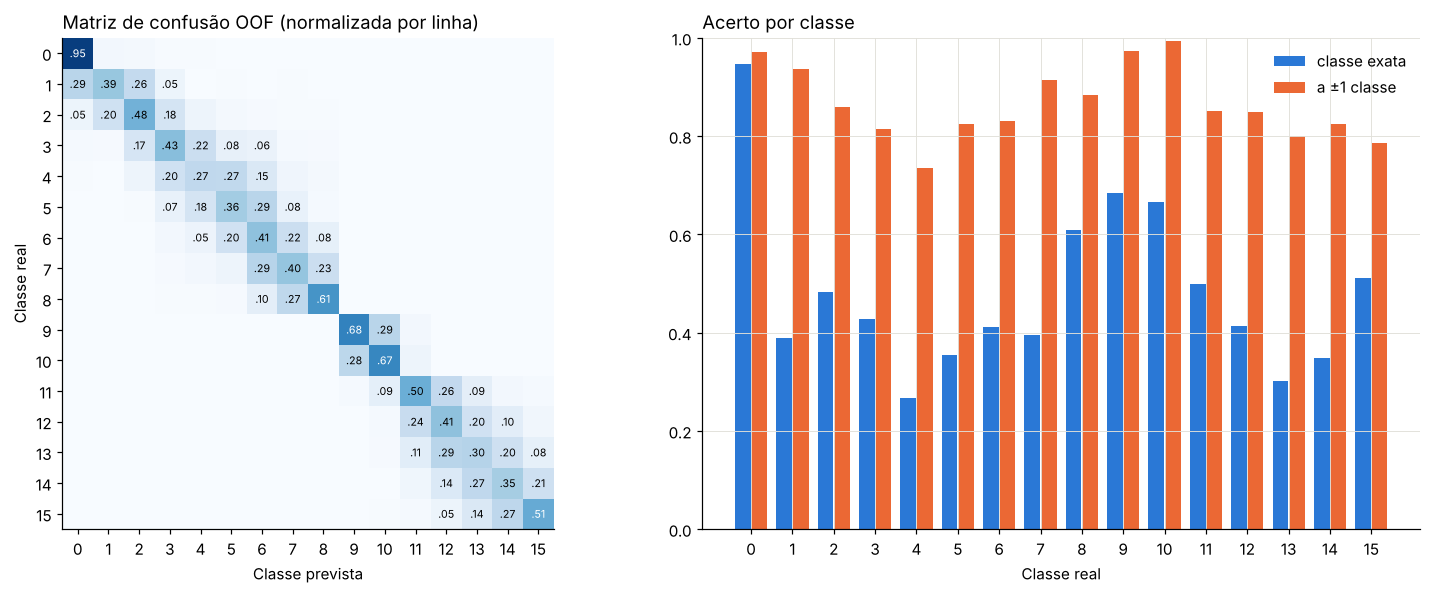

In [9]:
pred_oof = predict(p_oof)
ref = {"macroF1": f1(pred_oof), "acc": float(np.mean(pred_oof == y_all)), "MAE": float(np.abs(pred_oof - y_all).mean()),
       "a ≤1 classe": float(np.mean(np.abs(pred_oof - y_all) <= 1)),
       "QWK": cohen_kappa_score(y_all, pred_oof, weights="quadratic")}
print({k: round(v, 4) for k, v in ref.items()})

per_class = pd.DataFrame({"suporte": np.bincount(y_all, minlength=K),
                          "F1": f1_score(y_all, pred_oof, average=None),
                          "acerto exato": [np.mean(pred_oof[y_all == k] == k) for k in range(K)],
                          "acerto ±1 classe": [np.mean(np.abs(pred_oof[y_all == k] - k) <= 1) for k in range(K)]})
per_class.index.name = "classe"
print(per_class.round(3).T.to_string())

cm = confusion_matrix(y_all, pred_oof); cmn = cm / cm.sum(1, keepdims=True)
fig, ax = plt.subplots(1, 2, figsize=(14, 5.5), gridspec_kw={"width_ratios": [1.1, 1]})
ax[0].grid(False); im = ax[0].imshow(cmn, cmap="Blues", vmin=0, vmax=1)
for i in range(K):
    for j in range(K):
        if cmn[i, j] >= .05:
            ax[0].text(j, i, f"{cmn[i, j]:.2f}"[1:], ha="center", va="center", fontsize=7,
                       color="white" if cmn[i, j] > .5 else "black")
ax[0].set_xticks(range(K)); ax[0].set_yticks(range(K)); ax[0].set_xlabel("Classe prevista"); ax[0].set_ylabel("Classe real")
ax[0].set_title("Matriz de confusão OOF (normalizada por linha)", loc="left")
x = np.arange(K)
ax[1].bar(x - .2, per_class["acerto exato"], .38, color=AZUL, label="classe exata")
ax[1].bar(x + .2, per_class["acerto ±1 classe"], .38, color=LARANJA, label="a ±1 classe")
ax[1].set_xticks(x); ax[1].set_xlabel("Classe real"); ax[1].set_ylim(0, 1); ax[1].legend(frameon=False)
ax[1].set_title("Acerto por classe", loc="left")
plt.tight_layout(); plt.show()

### 7.1 Porque é que algumas classes têm F1 baixo
Para cada classe: suporte (nº de pessoas no treino), F1, probabilidade média que o modelo dá à classe certa e às
duas vizinhas, % dos erros que caem numa classe vizinha e a classe com que é mais confundida.

,faixa,suporte,% do treino,F1,P(classe certa),P(classes vizinhas),% erros p/ vizinha,mais confundida com,% p/ essa classe
classe,,,,,,,,,
0,15–17,207,1.89,0.81,0.76,0.18,45.45,1,2.42
1,18–19,172,1.57,0.40,0.35,0.55,89.52,0,29.07
2,20–24,399,3.64,0.53,0.36,0.40,72.82,1,20.05
3,25–29,377,3.44,0.41,0.29,0.41,67.59,4,22.02
4,30–34,449,4.10,0.28,0.24,0.41,63.83,5,26.50
5,35–39,647,5.90,0.37,0.29,0.42,72.66,6,29.21
6,40–44,859,7.84,0.38,0.29,0.43,71.15,7,22.24
7,45–49,862,7.86,0.40,0.32,0.47,85.99,6,29.47
8,50–54,905,8.26,0.63,0.50,0.28,69.97,7,27.29


Correlação (Spearman) entre suporte e F1: rho = 0.20 (p = 0.46)


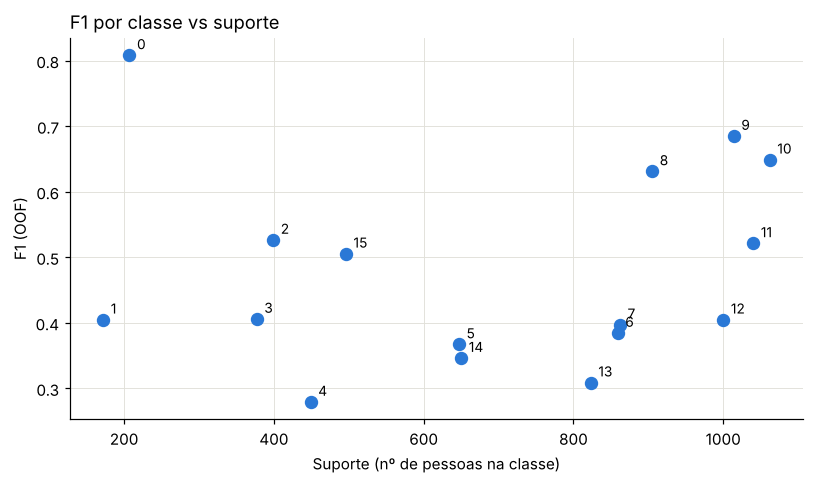

In [10]:
from scipy.stats import spearmanr
FAIXAS = ["15–17", "18–19", "20–24", "25–29", "30–34", "35–39", "40–44", "45–49", "50–54", "55–59",
          "60–64", "65–69", "70–74", "75–79", "80–84", "85+"]
rows = []
for k in range(K):
    m = y_all == k
    wrong = pred_oof[m][pred_oof[m] != k]
    vc = pd.Series(wrong).value_counts()
    viz = [j for j in (k - 1, k + 1) if 0 <= j < K]
    rows.append({"faixa": FAIXAS[k], "suporte": int(m.sum()), "% do treino": m.mean() * 100,
                 "F1": per_class.loc[k, "F1"], "P(classe certa)": p_oof[m, k].mean(),
                 "P(classes vizinhas)": p_oof[m][:, viz].sum(1).mean(),
                 "% erros p/ vizinha": np.mean(np.abs(wrong - k) == 1) * 100 if len(wrong) else np.nan,
                 "mais confundida com": int(vc.index[0]) if len(vc) else -1,
                 "% p/ essa classe": vc.iloc[0] / m.sum() * 100 if len(vc) else 0.0})
cls = pd.DataFrame(rows); cls.index.name = "classe"
display(cls.round(2))
rho, pv = spearmanr(cls["suporte"], cls["F1"])
print(f"Correlação (Spearman) entre suporte e F1: rho = {rho:.2f} (p = {pv:.2f})")

fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.scatter(cls["suporte"], cls["F1"], s=60, color=AZUL, zorder=3)
for k, r in cls.iterrows():
    ax.annotate(str(k), (r["suporte"], r["F1"]), xytext=(5, 4), textcoords="offset points", fontsize=9)
ax.set_xlabel("Suporte (nº de pessoas na classe)"); ax.set_ylabel("F1 (OOF)")
ax.set_title("F1 por classe vs suporte", loc="left"); plt.tight_layout(); plt.show()

**Discussão.**
- **Não há evidência de que o suporte explique o F1.** A correlação entre o nº de pessoas por classe e o F1 é
  fraca e não significativa (ρ ≈ 0.20, p ≈ 0.46) — com 16 classes isto não prova que o suporte não tenha efeito,
  apenas que não é visível nestes dados. A classe 4 (30–34 anos, 449 pessoas) tem F1 0.28, enquanto a classe 0
  (15–17, 207 pessoas) tem 0.81 e a 1 (18–19, só 172 pessoas) tem 0.40. Pouca representação não parece ser o
  problema principal, por isso é pouco provável que reamostragem (SMOTE, *oversampling*) resolva muito.
- **O que pesa é a separabilidade entre faixas vizinhas.** Nas classes 4, 13 e 14 o modelo atribui, em média,
  **mais probabilidade às duas classes vizinhas (0.41–0.45) do que à classe certa (0.24–0.28)**, e 64–73% dos
  erros caem numa faixa vizinha (4 ↔ 5, 13 ↔ 12, 14 ↔ 13). Faixas de 5 anos são estreitas para perfis que mudam
  devagar: entre os 30 e os 40 anos, ou entre os 75 e os 85, não há marcadores de etapa de vida no questionário.
- **As classes fáceis têm marcadores claros.** 15–17 (estudantes, a viver com os pais), 50–64 (fronteira dos
  módulos que só se perguntam a partir dos 55 anos) e 85+ (só tem uma vizinha). A classe 1 (18–19) é estreita
  (2 anos) e confunde-se sobretudo com a 0.
- **Implicação para o relatório.** O F1 macro penaliza igualmente acertar na faixa ao lado e falhar por 30 anos;
  o acerto a ±1 classe (≈ 87%) e o QWK (≈ 0.96) mostram que o modelo ordena bem as idades, mesmo quando não
  acerta na faixa exata.

## 8. Avaliação honesta (problemas 4 e 5)
A configuração (arquitetura, épocas, λ, variáveis) foi escolhida a olhar para os folds com `random_state=42`,
por isso o F1 desses folds é ligeiramente otimista. Duas verificações:
1. **Intervalo de confiança bootstrap** (2000 reamostragens) do F1 macro OOF.
2. **CV repetida com outras partições** (`random_state` 1–6), nunca usadas em nenhuma escolha (a partição 7
   foi usada para escolher o nº de épocas e por isso fica de fora).

In [11]:
rng = np.random.default_rng(SEED)
boot = [f1_score(y_all[i], pred_oof[i], average="macro") for i in (rng.integers(0, len(y_all), len(y_all)) for _ in range(2000))]
lo, hi = np.percentile(boot, [2.5, 97.5])
print(f"F1 OOF (folds 42): {ref['macroF1']:.4f} | IC 95% bootstrap: [{lo:.4f}, {hi:.4f}]")
print(f"Entre folds: {main['info'].f1_fold.mean():.4f} ± {main['info'].f1_fold.std():.4f} "
      f"(mín {main['info'].f1_fold.min():.4f}, máx {main['info'].f1_fold.max():.4f})")

rep = [dict(particao=SEED, F1_OOF=ref["macroF1"])]
for s in REPEAT_SEEDS:
    r = run_cv(X_all, y_all, seed=s, tag=f"partição {s}")
    p_r = to_probs(r["oof"])
    rep.append(dict(particao=s, F1_OOF=f1_score(y_all, predict(p_r), average="macro")))
rep = pd.DataFrame(rep)
display(rep.round(4).T)
novas = rep[rep.particao != SEED].F1_OOF
F1_HONESTO = novas.mean() if len(novas) else ref["macroF1"]
if len(novas):
    print(f"Média em {len(novas)} partições não usadas nas escolhas: {F1_HONESTO:.4f} "
          f"(dp entre partições {novas.std():.4f}; mín {novas.min():.4f}, máx {novas.max():.4f})")
print(f"\nResultado a reportar: F1 macro ≈ {F1_HONESTO:.3f} ± 0.01 "
      f"(± ≈ meia largura do IC bootstrap, {(hi - lo) / 2:.3f})")

F1 OOF (folds 42): 0.4767 | IC 95% bootstrap: [0.4663, 0.4861]
Entre folds: 0.4765 ± 0.0192 (mín 0.4474, máx 0.4982)


partição 1 fold 0: F1 treino=0.6302 | F1 fold=0.4636 (15s)


partição 1 fold 1: F1 treino=0.6444 | F1 fold=0.4861 (15s)


partição 1 fold 2: F1 treino=0.6445 | F1 fold=0.4823 (15s)


partição 1 fold 3: F1 treino=0.6323 | F1 fold=0.4676 (16s)


partição 1 fold 4: F1 treino=0.6389 | F1 fold=0.4823 (15s)


... (23 outputs left out)

partição 6 fold 3: F1 treino=0.6374 | F1 fold=0.4627 (15s)


partição 6 fold 4: F1 treino=0.6411 | F1 fold=0.4542 (15s)


,0,1,2,3,4,5,6
particao,42.0000,1.0000,2.0000,3.0000,4.0000,5.0000,6.0000
F1_OOF,0.4767,0.4766,0.4771,0.4773,0.4723,0.4713,0.4732


Média em 6 partições não usadas nas escolhas: 0.4746 (dp entre partições 0.0027; mín 0.4713, máx 0.4773)

Resultado a reportar: F1 macro ≈ 0.475 ± 0.01 (± ≈ meia largura do IC bootstrap, 0.010)


**Como reportar este número.** As partições novas protegem contra o ajuste a *uma* divisão específica, mas não
eliminam o viés de seleção: a arquitetura, as épocas, λ e as variáveis foram escolhidos com as mesmas 10 962
linhas. Além disso:
- o desvio-padrão entre partições (≈ 0.003) mede só a variabilidade da divisão em folds, **não** a incerteza de
  generalização;
- o IC bootstrap (≈ ± 0.01) é mais realista, mas também ignora a variabilidade do próprio treino da rede.

Por isso o resultado deve ser apresentado como **F1 macro ≈ 0.475 ± 0.01** (estimativa interna, possivelmente
ligeiramente otimista). A única avaliação verdadeiramente independente é o **leaderboard** do Kaggle.

### 8.1 Sensibilidade: membros do mesmo agregado familiar
Se houvesse várias pessoas do mesmo agregado, umas no treino e outras na validação, a CV poderia ser otimista.
O dataset **não tem identificador de agregado**: `HHID = PID × 100 + nº de ordem` e cada `PID` aparece uma só
vez (nenhum repetido no treino nem partilhado com o teste). Como aproximação, agrupam-se as pessoas pelo
**perfil do agregado** (11 variáveis: região, urbanização, nº de pessoas, nº de crianças, tipo, ativos,
inativos, rendimento, ano e mês da entrevista) e repete-se a CV com `StratifiedGroupKFold`, que nunca põe o
mesmo perfil no treino e na validação.

Esta aproximação é **pessimista**: além de separar eventuais membros do mesmo agregado, obriga o modelo a
prever perfis de agregado que nunca viu. Uma descida pequena é compatível com "sem leakage relevante".

In [12]:
from sklearn.model_selection import StratifiedGroupKFold
if RUN_GROUP_SENSITIVITY:
    print("HHID // 100 == PID em todas as linhas:", bool(((train.HHID // 100) == train.PID).all()),
          "| PID repetidos:", int(train.PID.duplicated().sum()),
          "| PID partilhados com o teste:", len(set(train.PID) & set(test.PID)))
    HH_KEY = ["REGION", "NUTS2_AG", "DEG_URB", "HHNBPERS_COD", "HHNBPERS_0_13_COD", "HHTYPE",
              "HH_ACT", "HH_INACT", "HHINCOME", "REFYEAR", "REFMONTH"]
    groups = train[HH_KEY].astype(str).agg("|".join, axis=1)
    print(f"Perfis de agregado distintos: {groups.nunique()} | pessoas que partilham o perfil com outra: "
          f"{(groups.groupby(groups).transform('size') > 1).mean():.1%}")
    g_folds = list(StratifiedGroupKFold(N_FOLDS, shuffle=True, random_state=SEED).split(X_all, y_all, groups))
    r_g = run_cv(X_all, y_all, folds=g_folds, tag="agrupada")
    p_g = to_probs(r_g["oof"])
    f1_g = f1_score(y_all, predict(p_g), average="macro")
    print(f"\nF1 OOF: estratificada {ref['macroF1']:.4f} | agrupada por perfil de agregado {f1_g:.4f} "
          f"(diferença {f1_g - ref['macroF1']:+.4f}; IC 95% bootstrap da estratificada: [{lo:.4f}, {hi:.4f}])")

HHID // 100 == PID em todas as linhas: True | PID repetidos: 0 | PID partilhados com o teste: 0


Perfis de agregado distintos: 6044 | pessoas que partilham o perfil com outra: 60.3%


agrupada fold 0: F1 treino=0.6530 | F1 fold=0.4842 (15s)


agrupada fold 1: F1 treino=0.6415 | F1 fold=0.4884 (15s)


agrupada fold 2: F1 treino=0.6376 | F1 fold=0.4765 (16s)


agrupada fold 3: F1 treino=0.6341 | F1 fold=0.4475 (14s)


agrupada fold 4: F1 treino=0.6284 | F1 fold=0.4893 (15s)



F1 OOF: estratificada 0.4767 | agrupada por perfil de agregado 0.4773 (diferença +0.0006; IC 95% bootstrap da estratificada: [0.4663, 0.4861])


## 9. Diagnóstico de overfitting (problema 6)

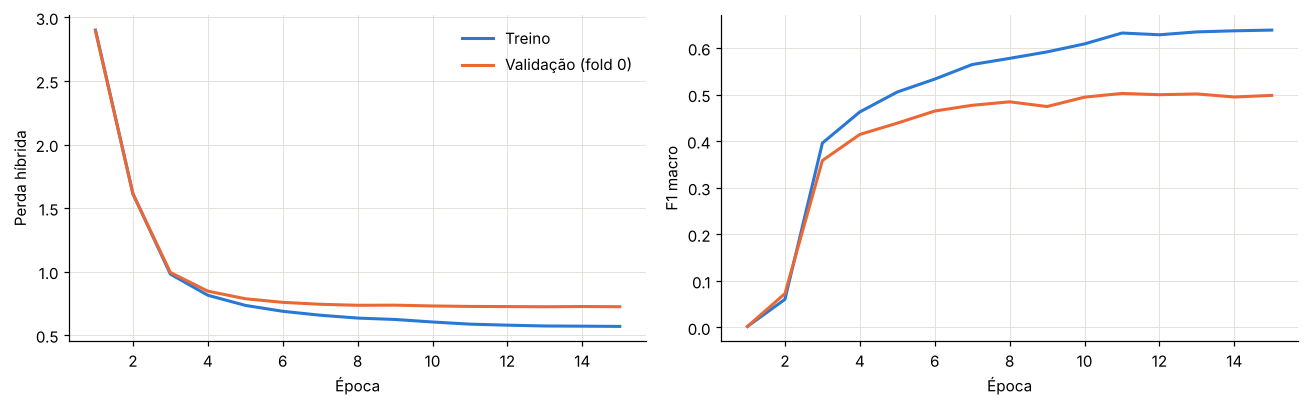

,fold,f1_treino,f1_fold,segundos
0,0,0.6384,0.4982,18
1,1,0.6409,0.4884,16
2,2,0.6440,0.4733,15
3,3,0.6485,0.4474,15
4,4,0.6400,0.4753,15


F1 treino 0.642 vs fora do fold 0.477 -> gap 0.166
Perda de validação: mínimo 0.7237 (época 13), final 0.7240


In [13]:
h = main["models"][0].hist
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].plot(h.epoca, h.loss_treino, color=AZUL, lw=2, label="Treino")
ax[0].plot(h.epoca, h.loss_val, color=LARANJA, lw=2, label="Validação (fold 0)")
ax[0].set_ylabel("Perda híbrida"); ax[0].set_xlabel("Época"); ax[0].legend(frameon=False)
ax[1].plot(h.epoca, h.f1_treino, color=AZUL, lw=2); ax[1].plot(h.epoca, h.f1_val, color=LARANJA, lw=2)
ax[1].set_ylabel("F1 macro"); ax[1].set_xlabel("Época")
plt.tight_layout(); plt.show()
info = main["info"]; display(info.round(4))
print(f"F1 treino {info.f1_treino.mean():.3f} vs fora do fold {info.f1_fold.mean():.3f} -> "
      f"gap {info.f1_treino.mean() - info.f1_fold.mean():.3f}")
print(f"Perda de validação: mínimo {h.loss_val.min():.4f} (época {int(h.loc[h.loss_val.idxmin(), 'epoca'])}), "
      f"final {h.loss_val.iloc[-1]:.4f}")

**Escolha da regularização (medida em duas partições, `random_state` 42 e 7).**

| Variante | F1 OOF (42 / 7) | F1 treino | Gap |
|---|---|---|---|
| 20 épocas (versão `04`) | 0.481 / 0.478 | 0.69 | 0.21 |
| 20 épocas, binárias fora do QuantileTransformer | 0.481 / 0.478 (idêntico) | 0.69 | 0.21 |
| 20 épocas, dropout 0.5, emb. dropout 0.3, wd 0.1 | 0.477 / 0.472 | 0.60 | 0.12 |
| **15 épocas (escolhida)** | 0.476 / 0.480 | 0.64 | **0.16** |

- Tirar as binárias do QuantileTransformer não muda nada: numa coluna 0/1 a transformação é afim e a
  BatchNorm de entrada anula-a. Fica a versão mais limpa.
- Mais regularização reduz bastante o gap mas custa ~0.5 pontos de F1. **15 épocas** reduz o gap em ~25% sem
  perder F1 (média 0.478 vs 0.479) → é a versão usada.
- O gap que resta (~0.16) é memorização de ~8.8 mil exemplos por fold com ~380 variáveis; a perda de
  validação não volta a subir, por isso o modelo não está a degradar com o treino.

### 9.1 Learning curve — o gap vem da falta de dados?
Treina-se o modelo final com 25%, 50%, 75% e 100% do treino do fold 0, **3 vezes por ponto** (subamostra e
inicialização diferentes), e avalia-se sempre no mesmo fold de validação; mostra-se média ± desvio-padrão.

Como o nº de épocas é fixo (15) e o OneCycle escala com o nº de lotes, com 25% dos dados o modelo faria só 1/4
das atualizações. Para separar **quantidade de dados** de **quantidade de treino**, há duas versões:
- **mesmas épocas** (15): menos dados → menos passos de otimização;
- **mesmos passos**: as épocas sobem para 15 / fração (60, 30, 20, 15), para todas as versões fazerem o mesmo
  nº de atualizações que o modelo final. Se o gap encolher e o F1 de validação subir com mais dados, o overfitting é sobretudo **variância**
(poucos exemplos para o nº de parâmetros) e não um problema de configuração.

epocas passos f1_treino         f1_validacao          \
                         mean   mean      mean     std         mean     std   
versao        n_treino                                                        
mesmas épocas 2192       15.0  135.0    0.6359  0.0010       0.3801  0.0047   
              4384       15.0  270.0    0.6578  0.0104       0.4517  0.0017   
              6576       15.0  390.0    0.6610  0.0060       0.4775  0.0130   
              8769       15.0  525.0    0.6405  0.0023       0.4914  0.0079   
mesmos passos 2192       60.0  540.0    0.9967  0.0011       0.4103  0.0101   
              4384       30.0  540.0    0.8139  0.0114       0.4617  0.0068   
              6576       20.0  520.0    0.7202  0.0075       0.4831  0.0116   
              8769       15.0  525.0    0.6405  0.0023       0.4914  0.0079   

                           gap          
                          mean     std  
versao        n_treino                  
mesmas épocas 2192      0.2558  0.0037  
              4384      0.2061  0.0092  
              6576      0.1835  0.0182  
              8769      0.1491  0.0102  
mesmos passos 2192      0.5863  0.0111  
              4384      0.3522  0.0128  
              6576      0.2371  0.0160  
              8769      0.1491  0.0102

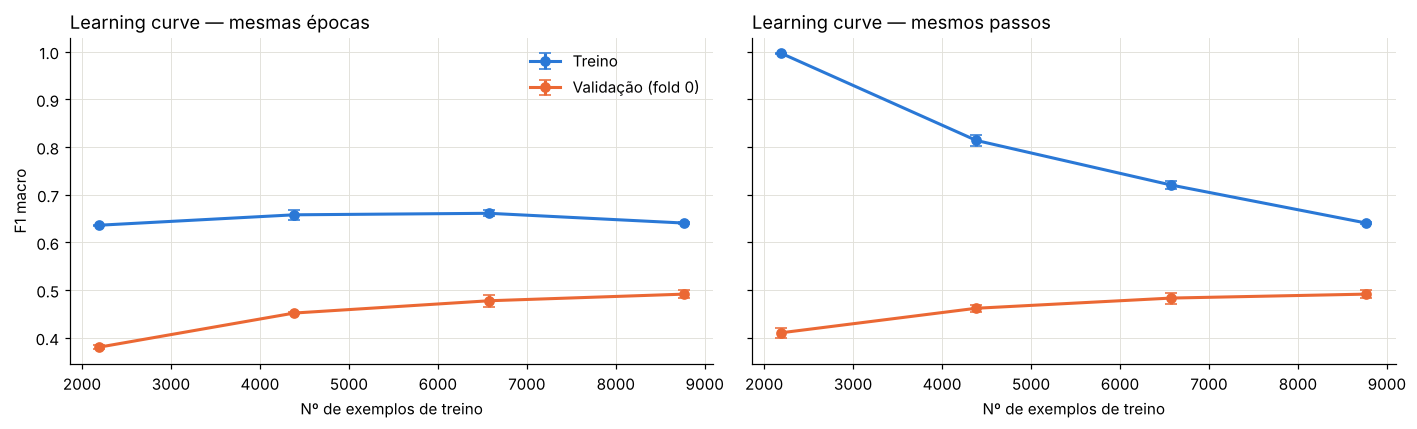

In [14]:
from sklearn.model_selection import train_test_split
a0, b0 = FOLDS[0]; runs = []
LC_SEEDS = [0, 1, 2]   # subamostra e inicialização diferentes em cada semente
for versao in ["mesmas épocas", "mesmos passos"]:
    for frac in [0.25, 0.5, 0.75, 1.0]:
        ep = EPOCHS if versao == "mesmas épocas" else int(round(EPOCHS / frac))
        if versao == "mesmos passos" and frac == 1.0:     # igual à versão "mesmas épocas": reutiliza-se
            runs += [{**r, "versao": versao} for r in runs if r["versao"] == "mesmas épocas" and r["fracao"] == 1.0]
            continue
        for sd in LC_SEEDS:
            idx = a0 if frac == 1.0 else train_test_split(a0, train_size=frac, stratify=y_all[a0], random_state=sd)[0]
            m_lc = train_mlp(X_all.iloc[idx], y_all[idx], main["num"], main["cat"], seed=SEED + sd, epochs=ep)
            runs.append(dict(versao=versao, fracao=frac, epocas=ep, semente=sd, n_treino=len(idx),
                             passos=ep * int(np.ceil(len(idx) / BATCH)),
                             f1_treino=f1_score(y_all[idx], to_probs(m_lc.logits(X_all.iloc[idx])).argmax(1), average="macro"),
                             f1_validacao=f1_score(y_all[b0], to_probs(m_lc.logits(X_all.iloc[b0])).argmax(1), average="macro")))
runs = pd.DataFrame(runs); runs["gap"] = runs.f1_treino - runs.f1_validacao
lc = runs.groupby(["versao", "n_treino"])[["epocas", "passos", "f1_treino", "f1_validacao", "gap"]].agg(["mean", "std"])
lc = lc.drop(columns=[("epocas", "std"), ("passos", "std")])
display(lc.round(4))
fig, axs = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, versao in zip(axs, ["mesmas épocas", "mesmos passos"]):
    g = runs[runs.versao == versao].groupby("n_treino")[["f1_treino", "f1_validacao"]].agg(["mean", "std"])
    for col, cor, lab in [("f1_treino", AZUL, "Treino"), ("f1_validacao", LARANJA, "Validação (fold 0)")]:
        ax.errorbar(g.index, g[(col, "mean")], yerr=g[(col, "std")], fmt="o-", color=cor, lw=2, capsize=4, label=lab)
    ax.set_xlabel("Nº de exemplos de treino"); ax.set_title(f"Learning curve — {versao}", loc="left")
axs[0].set_ylabel("F1 macro"); axs[0].legend(frameon=False)
plt.tight_layout(); plt.show()

**Leitura (média de 3 treinos por ponto).**
- **Mesmas épocas:** o F1 de validação sobe de 0.380 para 0.491 (25% → 100% dos dados) e o gap desce de 0.256
  para 0.149.
- **Mesmos passos** (todas as versões fazem ~525–540 atualizações): o F1 de validação sobe de 0.410 para 0.491.
  Com 25% dos dados e 60 épocas, o modelo decora o treino (F1 de treino 0.997) e o gap é 0.586; o gap desce de
  forma monótona até 0.149 com os dados todos.
- **Conclusão.** Parte da subida na versão "mesmas épocas" vinha de menos treino (com 25% dos dados, igualar o nº de
  passos sobe o F1 de validação de 0.380 para 0.410), mas a maior parte vem dos **dados**: mesmo com o mesmo nº de
  passos, passar de 25% para 100% dos dados sobe o F1 de validação em ~0.08 e reduz muito o gap. Isto apoia a
  interpretação de que o gap é sobretudo **variância por falta de dados**. Limites: um só fold de validação, 3
  sementes por ponto, e não prova que mais dados fechariam o gap.

*Nota:* no ponto de 100% a subamostra é sempre a mesma (só muda a inicialização), por isso o seu desvio-padrão é
menor por construção e não é comparável com o dos outros pontos.

## 10. Importância das variáveis (permutação, média dos 5 folds)
Cada modelo é avaliado no seu próprio fold de validação; baralha-se uma variável (ou um **grupo**) e mede-se o
aumento da perda. A importância individual subestima variáveis correlacionadas (as outras compensam), por isso
também se mede por grupos.

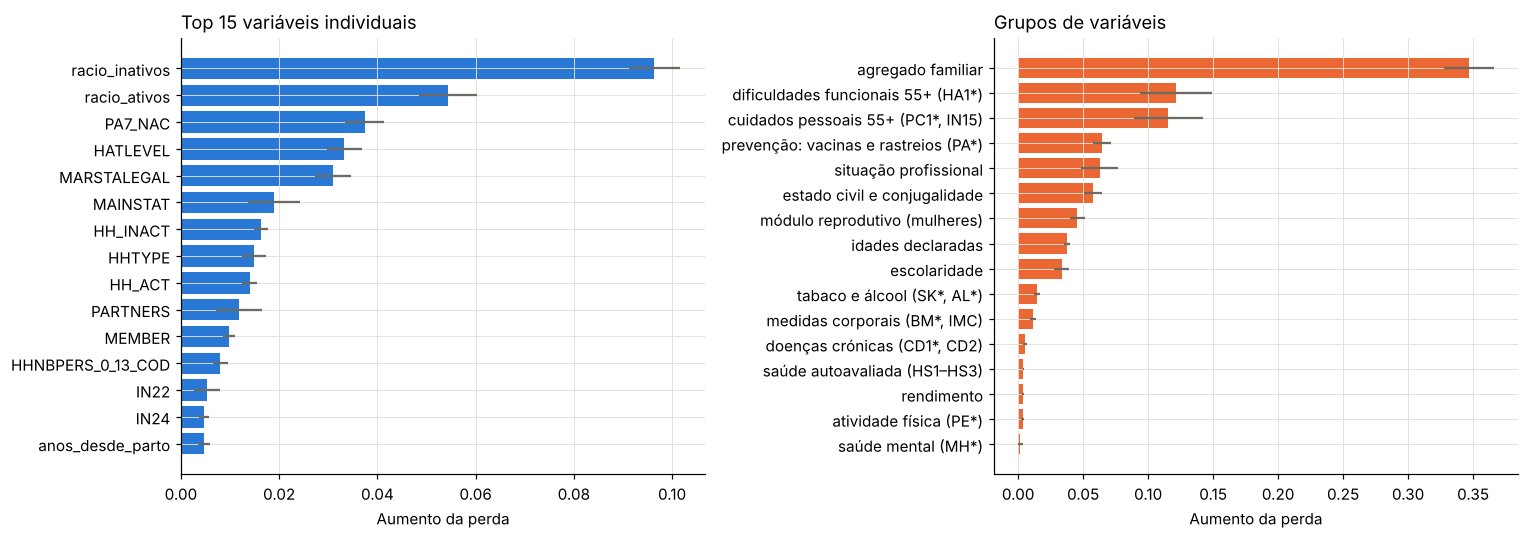

,aumento_perda,dp_folds
agregado familiar,0.3470,0.0192
dificuldades funcionais 55+ (HA1*),0.1214,0.0278
"cuidados pessoais 55+ (PC1*, IN15)",0.1155,0.0263
prevenção: vacinas e rastreios (PA*),0.0646,0.0070
situação profissional,0.0626,0.0144
estado civil e conjugalidade,0.0577,0.0069
módulo reprodutivo (mulheres),0.0454,0.0056
idades declaradas,0.0377,0.0025
escolaridade,0.0334,0.0056
"tabaco e álcool (SK*, AL*)",0.0145,0.0023


In [15]:
BASES = sorted({base_name(c) for c in main["num"] + main["cat"]})
fam = lambda rx: [c for c in BASES if re.match(rx, c)]
GROUPS = {"dificuldades funcionais 55+ (HA1*)": fam(r"^HA1"),
          "cuidados pessoais 55+ (PC1*, IN15)": fam(r"^PC1") + ["IN15"],
          "doenças crónicas (CD1*, CD2)": fam(r"^CD"),
          "agregado familiar": HOUSEHOLD,
          "módulo reprodutivo (mulheres)": WOMEN_MODULE,
          "idades declaradas": DECLARED_AGE,
          "situação profissional": ["MAINSTAT", "JOBSTAT_COD", "JOBISCO_COD", "LOCNACE_COD", "FT_PT"],
          "estado civil e conjugalidade": ["MARSTALEGAL", "PARTNERS"],
          "escolaridade": ["HATLEVEL"],
          "rendimento": ["HHINCOME"],
          "prevenção: vacinas e rastreios (PA*)": fam(r"^PA\d"),
          "saúde autoavaliada (HS1–HS3)": fam(r"^HS\d"),
          "atividade física (PE*)": fam(r"^PE\d"),
          "tabaco e álcool (SK*, AL*)": fam(r"^(SK|AL)\d"),
          "saúde mental (MH*)": fam(r"^MH\d"),
          "medidas corporais (BM*, IMC)": fam(r"^BM\d") + ["IMC"]}


def permutation_importance(res, X, y, groups, repeats=3):
    rng = np.random.default_rng(SEED); out = {}
    for m, (_, b) in zip(res["models"], res["folds"]):
        xn, xc = m.pre.transform(X.iloc[b]); yb = torch.from_numpy(y[b])
        base = hybrid_loss(m.logits(arrays=(xn, xc)), yb, m.w).item()
        for g, cols in groups.items():
            jn = [j for j, c in enumerate(res["num"]) if base_name(c) in cols or c in cols]
            jc = [j for j, c in enumerate(res["cat"]) if base_name(c) in cols or c in cols]
            d = []
            for _ in range(repeats):
                perm = rng.permutation(len(b)); a_, c_ = xn.copy(), xc.copy()
                a_[:, jn] = xn[perm][:, jn]; c_[:, jc] = xc[perm][:, jc]
                d.append(hybrid_loss(m.logits(arrays=(a_, c_)), yb, m.w).item() - base)
            out.setdefault(g, []).append(np.mean(d))
    return pd.DataFrame({"aumento_perda": {g: np.mean(v) for g, v in out.items()},
                         "dp_folds": {g: np.std(v) for g, v in out.items()}}).sort_values("aumento_perda", ascending=False)


single = {g: [g] for g in sorted({base_name(c) for c in main["num"] + main["cat"]})}
imp = permutation_importance(main, X_all, y_all, single, repeats=2)
imp_g = permutation_importance(main, X_all, y_all, GROUPS)
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
top = imp.head(15)[::-1]
ax[0].barh(top.index, top.aumento_perda, xerr=top.dp_folds, color=AZUL, ecolor=CINZA)
ax[0].set_title("Top 15 variáveis individuais", loc="left"); ax[0].set_xlabel("Aumento da perda")
g = imp_g[::-1]
ax[1].barh(g.index, g.aumento_perda, xerr=g.dp_folds, color=LARANJA, ecolor=CINZA)
ax[1].set_title("Grupos de variáveis", loc="left"); ax[1].set_xlabel("Aumento da perda")
plt.tight_layout(); plt.show()
imp.to_csv(f"{OUT_DIR}/importancia_variaveis_mlp_corn.csv")
display(imp_g.round(4))

**Interpretação dos 5 grupos mais importantes** (aumento da perda ao baralhar o grupo; competição):
1. **Agregado familiar (0.35, de longe o maior).** A composição da casa marca a etapa de vida: o nº de ordem no
   agregado (3.º, 4.º… são quase sempre filhos), viver com crianças, o tipo de agregado (casal com filhos,
   pessoa só) e o nº de inativos (estudantes e reformados). Identifica sobretudo jovens a viver com os pais e
   idosos a viver sós ou em casal sem filhos. É informação demográfica e estrutural, não de saúde.
2. **Dificuldades funcionais 55+ (HA1\*, 0.12).** Módulo só perguntado a partir dos 55 anos: o "Não aplicável"
   separa < 55 de ≥ 55, e dentro dos 55+ o grau de dificuldade (ver, ouvir, andar, memória…) aumenta com a idade
   e ajuda a distinguir os 60 dos 80 anos.
3. **Cuidados pessoais 55+ (PC1\*, IN15, 0.12).** Mesma lógica: filtro dos 55 anos e, nos mais velhos, a
   dificuldade em atividades básicas (vestir, tomar banho, comer), que sobe nas faixas 75+.
4. **Vacinas e rastreios (PA\*, 0.065).** Os programas de saúde são definidos por idade: vacina da gripe
   recomendada a partir dos 65 anos, rastreios femininos (mamografia, citologia) e de outros cancros com
   idades-alvo. A data da última vacina/rastreio é, por isso, um marcador indireto de idade. (O "Não aplicável"
   dos rastreios femininos depende só do sexo, não da idade.)
5. **Situação profissional (0.063).** Estudante (sobretudo < 25), empregado (25–64), reformado (sobretudo 65+):
   um dos marcadores de etapa de vida mais diretos.

Seguem-se o estado civil (viuvez nas idades altas, solteiros nas baixas), o módulo reprodutivo das mulheres e
as idades declaradas. As variáveis de **saúde propriamente dita** (doenças crónicas, saúde autoavaliada, IMC,
atividade física) têm importância *marginal* pequena: a informação delas sobre a idade já está quase toda
contida nos grupos acima (por exemplo, quem tem dificuldades funcionais também tem mais doenças crónicas), e a
permutação só mede o que se perde quando o grupo desaparece. Isto **não** significa que a saúde não varie com a
idade — significa que, para *prever* a faixa etária, os marcadores estruturais e de etapa de vida dominam. Por
isso as discrepâncias de perfil (secção 12) usam modelos sem esses marcadores.

*Nota:* alguns grupos partilham variáveis (p. ex. `anos_desde_parto` está no módulo reprodutivo e nas idades
declaradas) e a permutação de grupos correlacionados não é aditiva, por isso os valores servem para ordenar,
não para somar.

## 11. Exportação para o stacking
Probabilidades (calibradas se a secção 5 o justificar; OOF no treino, média dos 5 folds no teste), idade esperada
Σ k·P(k), desvio-padrão ordinal e o **nº do fold** de cada linha de treino.

In [16]:
def ordinal_features(p):
    mu = p @ np.arange(K)
    sd = np.sqrt((p * (np.arange(K)[None, :] - mu[:, None]) ** 2).sum(1))
    df = pd.DataFrame(p, columns=[f"p{k}" for k in range(K)])
    df["idade_esperada"], df["dp_ordinal"] = mu, sd
    return df

np.save(f"{OUT_DIR}/mlp_corn_oof_probs.npy", p_oof)
np.save(f"{OUT_DIR}/mlp_corn_test_probs.npy", p_test)
f_oof = ordinal_features(p_oof)
f_oof.insert(0, "PID", train["PID"].values); f_oof.insert(1, TARGET, y_all); f_oof.insert(2, "fold", fold_id)
f_te = ordinal_features(p_test); f_te.insert(0, "RowId", sub["RowId"].values)
f_oof.to_csv(f"{OUT_DIR}/mlp_corn_oof_features.csv", index=False)
f_te.to_csv(f"{OUT_DIR}/mlp_corn_test_features.csv", index=False)
p_test_folds = np.stack([to_probs(l, T) for l, T in zip(main["test"], T_FOLDS)])
np.save(f"{OUT_DIR}/mlp_corn_test_probs_por_fold.npy", p_test_folds)
print("Guardado: mlp_corn_oof_probs.npy", p_oof.shape, "| mlp_corn_test_probs.npy", p_test.shape,
      "| mlp_corn_test_probs_por_fold.npy", p_test_folds.shape)
print("          mlp_corn_oof_features.csv (com coluna 'fold') / mlp_corn_test_features.csv")

# Desalinhamento: OOF = 1 modelo por linha; teste = média de 5 modelos (mais suave)
ent = lambda p: -(p * np.log(p)).sum(1).mean()
al = pd.DataFrame({"P máxima média": [p_oof.max(1).mean(), p_test_folds.max(2).mean(), p_test.max(1).mean()],
                   "entropia média": [ent(p_oof), np.mean([ent(p) for p in p_test_folds]), ent(p_test)],
                   "dp_ordinal médio": [ordinal_features(p_oof).dp_ordinal.mean(),
                                        np.mean([ordinal_features(p).dp_ordinal.mean() for p in p_test_folds]),
                                        ordinal_features(p_test).dp_ordinal.mean()]},
                  index=["OOF treino (1 modelo)", "teste, 1 modelo (média dos 5)", "teste, média dos 5 modelos"])
display(al.round(4))

Guardado: mlp_corn_oof_probs.npy (10962, 16) | mlp_corn_test_probs.npy (3655, 16) | mlp_corn_test_probs_por_fold.npy (5, 3655, 16)
          mlp_corn_oof_features.csv (com coluna 'fold') / mlp_corn_test_features.csv


,P máxima média,entropia média,dp_ordinal médio
OOF treino (1 modelo),0.5007,1.2423,1.3217
"teste, 1 modelo (média dos 5)",0.4975,1.2482,1.3239
"teste, média dos 5 modelos",0.4834,1.2780,1.3476


**Desalinhamento no stacking.** No treino, cada linha OOF vem de **um** modelo; no teste, as probabilidades são a
**média de 5** modelos, por isso ficam mais suaves (P máxima um pouco menor, entropia e `dp_ordinal` maiores — ver
tabela). Um meta-modelo treinado nas OOF vê no teste distribuições ligeiramente diferentes. Duas formas de o evitar:
1. **Aplicar o meta-modelo a cada uma das 5 matrizes de teste** (`mlp_corn_test_probs_por_fold.npy`, forma
   5 × N × 16) e fazer a média das previsões do meta-modelo — o meta-modelo vê sempre "um modelo por linha".
2. Usar no meta-modelo sobretudo features pouco sensíveis à suavização, como `idade_esperada` (a média muda
   pouco); as probabilidades individuais e o `dp_ordinal` são as mais afetadas.

## 12. Discrepâncias de perfil (problemas 1, 2, 3 e 7)
O modelo de competição usa informação que revela a idade sem dizer nada sobre a pessoa. Para estudar
discrepâncias entre a idade declarada e o perfil usam-se **dois modelos de perfil** (a mesma rede, os mesmos
folds, sem temperatura), cada um treinado com **5 sementes**; as listas finais vêm da **média das
probabilidades** das 5 sementes, o que torna as discrepâncias individuais mais estáveis (ver 12.2):

| Modelo | Variáveis |
|---|---|
| **A — perfil completo** | tudo **exceto** saltos do questionário (detetados dentro de cada fold), o módulo reprodutivo inteiro, as idades declaradas e a composição do agregado. Mantém saúde, hábitos **e** marcadores sociais (situação profissional, estado civil, escolaridade, rendimento, vacinas/rastreios). |
| **B — saúde e hábitos** | só estado de saúde (HS), doenças crónicas (CD), acidentes (AC), limitações sensoriais e físicas (PL), dor (PN), saúde mental (MH), internamentos (HO), consultas (AM), medicamentos (MD), medidas corporais (BM, IMC), atividade física (PE), tabaco (SK), álcool (AL), alimentação (DH) e o sexo. Sem marcadores sociais nem de política de saúde (PA\* — vacina da gripe e rastreios têm idades-alvo). |

**Escala em anos.** As faixas não têm a mesma largura (15–17 e 18–19 cobrem 3 e 2 anos; 85+ é aberta), por isso
um desvio de "3 classes" pode ser 5 ou 15 anos. Os desvios passam a ser medidos **em anos**, usando o ponto médio
de cada faixa (16, 18.5, 22, 27, …, 82 e 88 para 85+ — este último é uma convenção, porque a faixa é aberta):
- `idade_esperada_anos` = Σ P(k) · ponto médio(k); `dp_anos` = desvio-padrão dessa distribuição;
- `desvio_anos` = idade esperada − ponto médio da faixa real;
- `desvio_ajustado` = `desvio_anos` − desvio médio da faixa real (remove a atração das previsões para o centro);
- `z` = `desvio_ajustado` / `dp_anos`;
- **discrepância** se |`desvio_ajustado`| ≥ **15 anos** e `dp_anos` ≤ 12.5.

**Efeito de chão no modelo B.** A saúde e os hábitos quase não distinguem idades abaixo dos ~40 anos (um adulto
saudável de 25 ou de 35 anos tem um perfil de saúde parecido com o de um jovem de 16). Por isso, no modelo B,
um "perfil mais novo" só conta para pessoas com **40 ou mais anos** (faixa ≥ 40–44); abaixo disso, parecer mais
novo pela saúde não é atípico. A secção 12.2 mostra o efeito desta regra.

**Como interpretar.** Uma discrepância é apenas uma diferença grande entre a idade declarada e a idade que um
modelo estima — **não é um erro nos dados nem um diagnóstico de saúde**. Pode ter explicações de saúde, sociais
(p. ex. reforma antecipada, desemprego), demográficas ou erros de preenchimento. A hipótese de respostas dadas por
terceiros não pode ser testada: a variável `PROXY` é **constante** neste dataset (verificação abaixo). Os modelos
de perfil têm F1 baixo, por isso cada caso individual é incerto; as discrepâncias servem para **gerar hipóteses**
e caracterizar grupos, não para classificar pessoas.

In [17]:
print("PROXY no treino:", train["PROXY"].value_counts(dropna=False).to_dict(),
      "| no teste:", test["PROXY"].value_counts(dropna=False).to_dict(),
      "-> constante, não permite distinguir respostas próprias de respostas por terceiros")

MID = np.array([16, 18.5, 22, 27, 32, 37, 42, 47, 52, 57, 62, 67, 72, 77, 82, 88])   # ponto médio de cada faixa
MIN_CLASS_YOUNGER_B = 6                                                                # 40–44 anos
FIXED_EXCL = set(WOMEN_MODULE) | set(DECLARED_AGE) | set(HOUSEHOLD)
SEXV = train.SEX.values
BASES_ALL = sorted({base_name(c) for c in X_all.columns})
HEALTH_RX = r"^(HS|CD|AC|PL|PN|MH|HO|AM|MD|BM|PE|SK|AL|DH)"
NON_HEALTH = {b for b in BASES_ALL if not (re.match(HEALTH_RX, b) or b in ("IMC", "SEX"))}
SOCIAL = {"situação profissional": ["MAINSTAT", "JOBSTAT_COD", "JOBISCO_COD", "LOCNACE_COD", "FT_PT"],
          "estado civil": ["MARSTALEGAL", "PARTNERS"],
          "escolaridade": ["HATLEVEL"],
          "rendimento": ["HHINCOME"],
          "vacinas e rastreios (PA*)": [b for b in BASES_ALL if re.match(r"^PA\d", b)]}


def detected_skips(idx):
    """Saltos detetados SÓ com o treino do fold (sem olhar para o fold de validação)."""
    Xa, ya = X_all.iloc[idx], y_all[idx]
    return set(routing_columns(Xa, ya)) | set(skip_columns(Xa, ya, SEXV[idx]))


def excl_A(idx, extra=()):
    return detected_skips(idx) | FIXED_EXCL | set(extra)


def excl_B(idx, extra=()):
    return detected_skips(idx) | FIXED_EXCL | NON_HEALTH | set(extra)


def discrepancies(p, min_class_younger=0):
    mu = p @ MID
    d = pd.DataFrame({"PID": train["PID"].values, "real": y_all, "idade_real_anos": MID[y_all],
                      "idade_esperada_anos": mu,
                      "dp_anos": np.sqrt((p * (MID[None, :] - mu[:, None]) ** 2).sum(1))})
    d["desvio_anos"] = d.idade_esperada_anos - d.idade_real_anos
    d["desvio_ajustado"] = d.desvio_anos - d.groupby("real").desvio_anos.transform("mean")
    d["z"] = d.desvio_ajustado / d.dp_anos.clip(lower=2.5)
    ok = d.dp_anos <= 12.5
    d["tipo"] = np.select([(d.desvio_ajustado >= 15) & ok,
                           (d.desvio_ajustado <= -15) & ok & (d.real >= min_class_younger)],
                          ["perfil mais velho", "perfil mais novo"], "normal")
    return d


def run_seeds(exclude_fn, tag, n, offset=0):
    """O mesmo modelo, os mesmos folds (FOLDS), n sementes de treino diferentes (a partir de 'offset')."""
    return [run_cv(X_all, y_all, exclude_fn=exclude_fn, folds=FOLDS, seed=SEED + 1000 * (k + offset), tag=f"{tag} s{k + offset}")
            for k in range(n)]


runsA = run_seeds(excl_A, "perfil A", N_SEEDS_PROFILE)
runsB = run_seeds(excl_B, "perfil B", N_SEEDS_PROFILE)
profA, profB = runsA[0], runsB[0]
EXCL_FULL = set(ROUTING) | set(SKIPS) | FIXED_EXCL
same = all(ex == EXCL_FULL for r in runsA for ex in r["excls"])
print(f"Modelo A: {len(profA['excls'][0])} variáveis excluídas; deteção dentro de cada fold "
      f"{'igual' if same else 'DIFERENTE'} à deteção com os dados todos")
print(f"Modelo A: colunas por fold {profA['cols_per_fold']} | Modelo B: colunas por fold {profB['cols_per_fold']}")

pA_s = [to_probs(r["oof"]) for r in runsA]; pB_s = [to_probs(r["oof"]) for r in runsB]
pA, pB = np.mean(pA_s, 0), np.mean(pB_s, 0)          # média das sementes
anA = discrepancies(pA)
anB = discrepancies(pB, min_class_younger=MIN_CLASS_YOUNGER_B)
for nome, p, d in [("A — perfil completo", pA, anA), ("B — saúde e hábitos", pB, anB)]:
    print(f"{nome} (média de {N_SEEDS_PROFILE} sementes): F1 OOF = {f1_score(y_all, predict(p), average='macro'):.4f} | "
          f"QWK = {cohen_kappa_score(y_all, predict(p), weights='quadratic'):.3f} | discrepâncias: "
          f"{(d.tipo == 'perfil mais velho').sum()} mais velhos, {(d.tipo == 'perfil mais novo').sum()} mais novos")
print(f"(competição: F1 {ref['macroF1']:.4f})")

info_cols = pd.DataFrame({
    "SEX": train.SEX.values, "MAINSTAT": train.MAINSTAT.str[:30].values, "MARSTALEGAL": train.MARSTALEGAL.values,
    "HATLEVEL": train.HATLEVEL.values, "HS1": train.HS1.values, "HS3": train.HS3.str[:25].values,
    "IMC": X_all.IMC.round(1).values,
    "n_doencas_cronicas": (train.filter(regex="^CD1[A-P]$") == "Sim").sum(axis=1).values,
    # "Sem resposta" e valores em falta ficam como NaN (não contam como "não")
    "saude_ma": train.HS1.map({"Mau": 1.0, "Muito mau": 1.0, "Razoável": 0.0, "Bom": 0.0, "Muito bom": 0.0}).values,
    "limitado": train.HS3.map({"Severamente limitado": 1.0, "Limitado mas não severamente": 1.0,
                               "Nada limitado": 0.0}).values})
print("HS1 'Sem resposta'/em falta -> NaN:", int(info_cols.saude_ma.isna().sum()),
      "| HS3 'Sem resposta'/em falta -> NaN:", int(info_cols.limitado.isna().sum()))
anA = pd.concat([anA, info_cols], axis=1); anB = pd.concat([anB, info_cols], axis=1)

TIPOS = ["perfil mais velho", "perfil mais novo"]


def lists(p, mcy=0):
    d = discrepancies(p, mcy)
    return {t: set(d.PID[d.tipo == t]) for t in TIPOS}


def seed_fraction(p_list, mcy=0):
    """Para cada pessoa e tipo: fração das sementes (isoladas) em que é marcada."""
    out = pd.DataFrame(0.0, index=train["PID"].values, columns=TIPOS)
    for p in p_list:
        d = discrepancies(p, mcy)
        for t in TIPOS:
            out[t] += (d.tipo == t).values / len(p_list)
    return out


fracA, fracB = seed_fraction(pA_s), seed_fraction(pB_s, MIN_CLASS_YOUNGER_B)
for d, fr in [(anA, fracA), (anB, fracB)]:
    d["frac_sementes"] = np.select([d.tipo == t for t in TIPOS], [fr[t].values for t in TIPOS], np.nan)

PROXY no treino: {1.0: 10962} | no teste: {1.0: 3655} -> constante, não permite distinguir respostas próprias de respostas por terceiros


perfil A s0 fold 0: F1 treino=0.5532 | F1 fold=0.3969 (14s)


perfil A s0 fold 1: F1 treino=0.5591 | F1 fold=0.3983 (15s)


perfil A s0 fold 2: F1 treino=0.5578 | F1 fold=0.3861 (14s)


perfil A s0 fold 3: F1 treino=0.5600 | F1 fold=0.3537 (14s)


perfil A s0 fold 4: F1 treino=0.5546 | F1 fold=0.3744 (15s)


... (42 outputs left out)

perfil B s4 fold 2: F1 treino=0.3257 | F1 fold=0.2213 (9s)


perfil B s4 fold 3: F1 treino=0.3248 | F1 fold=0.2209 (9s)


perfil B s4 fold 4: F1 treino=0.3228 | F1 fold=0.2199 (9s)


Modelo A: 40 variáveis excluídas; deteção dentro de cada fold igual à deteção com os dados todos
Modelo A: colunas por fold [302, 302, 302, 302, 302] | Modelo B: colunas por fold [147, 147, 147, 147, 147]
A — perfil completo (média de 5 sementes): F1 OOF = 0.3925 | QWK = 0.933 | discrepâncias: 68 mais velhos, 86 mais novos
B — saúde e hábitos (média de 5 sementes): F1 OOF = 0.2283 | QWK = 0.803 | discrepâncias: 214 mais velhos, 341 mais novos
(competição: F1 0.4767)
HS1 'Sem resposta'/em falta -> NaN: 20 | HS3 'Sem resposta'/em falta -> NaN: 88


### 12.1 Efeito das correções
Por faixa: desvio médio em anos (atração para o centro), discrepâncias com o critério antigo (≥ 3 classes, sem
ajuste) e com o critério atual (≥ 15 anos, ajustado, com filtro de incerteza). No modelo B mostra-se também o
efeito da regra dos 40+ anos nos "mais novos".

In [18]:
dB_sem40 = pd.concat([discrepancies(pB), info_cols], axis=1)
tab = pd.DataFrame({
    "faixa": [f"{a}" for a in ["15–17", "18–19", "20–24", "25–29", "30–34", "35–39", "40–44", "45–49", "50–54",
                                "55–59", "60–64", "65–69", "70–74", "75–79", "80–84", "85+"]],
    "A: desvio médio (anos)": anA.groupby("real").desvio_anos.mean().values,
    "A: discrepantes": anA.groupby("real").tipo.apply(lambda t: (t != "normal").sum()).values,
    "B: desvio médio (anos)": anB.groupby("real").desvio_anos.mean().values,
    "B: mais novos sem regra 40+": dB_sem40.groupby("real").tipo.apply(lambda t: (t == "perfil mais novo").sum()).values,
    "B: mais novos com regra 40+": anB.groupby("real").tipo.apply(lambda t: (t == "perfil mais novo").sum()).values,
    "B: mais velhos": anB.groupby("real").tipo.apply(lambda t: (t == "perfil mais velho").sum()).values})
tab.index.name = "classe"
print(tab.round(1).T.to_string())
print(f"\nModelo B, 'mais novos': {(dB_sem40.tipo == 'perfil mais novo').sum()} sem a regra 40+ -> "
      f"{(anB.tipo == 'perfil mais novo').sum()} com a regra")

classe                          0      1      2      3      4      5      6      7      8      9      10     11     12     13     14    15
faixa                        15–17  18–19  20–24  25–29  30–34  35–39  40–44  45–49  50–54  55–59  60–64  65–69  70–74  75–79  80–84   85+
A: desvio médio (anos)         1.1    1.7    2.7    2.9    2.6    0.7   -0.3   -1.6   -2.0   -1.8   -0.8   -0.3   -0.8   -3.0   -4.5  -7.7
A: discrepantes                  0      2      9      5      5      8     21     10     15     29     16     21      4      6      0     3
B: desvio médio (anos)         8.2    8.4    8.5    5.7    4.2    1.8   -0.4   -1.8   -1.2   -2.2   -1.9   -3.7   -5.2   -7.7   -9.3 -11.9
B: mais novos sem regra 40+      0      0      0      0     10     27     28     60     79     68     36     33     11     18      5     3
B: mais novos com regra 40+      0      0      0      0      0      0     28     60     79     68     36     33     11     18      5     3
B: mais velhos             

### 12.2 Modelo A vs modelo B — porque é que as listas divergem?
A sobreposição entre as listas dos dois modelos é baixa, mas isso tem **duas explicações possíveis**: o modelo A
usa marcadores sociais, **ou** o modelo B é fraco e ruidoso. Três verificações:
1. **Sobreposição** das listas;
2. **Situação profissional** dos discrepantes do A que o B **não** encontra vs. os que ambos encontram — se os
   marcadores sociais explicam a diferença, devem concentrar-se no grupo "só A";
3. **Ablação social do modelo A**: retira-se um grupo social de cada vez (3 sementes por ablação) e compara-se a
   lista com a do modelo A completo. Para a comparação não depender do nº de pessoas marcadas (retirar um grupo
   pode aumentar ou diminuir a lista), comparam-se listas de **tamanho fixo**: os **N casos mais extremos por
   |z|** em cada direção, com N igual ao tamanho da lista final do A. A medida é o **Jaccard** entre o top-N de
   cada semente da ablação e o top-N de cada semente do A completo. A referência é o **ruído entre sementes**: o
   mesmo Jaccard entre pares de sementes do A completo (10 pares). Uma ablação só indica um efeito se o seu
   Jaccard médio ficar **abaixo de todo o ruído**.
4. **Controlo não social.** Retirar *qualquer* grupo informativo pode mudar as listas. Para saber se o efeito é
   específico dos marcadores sociais, retiram-se também **grupos de saúde** com as mesmas 3 sementes e o mesmo
   top-N: tabaco e álcool, medidas corporais e uma junção de grupos de saúde escolhida para ter importância
   parecida à das vacinas/rastreios. As importâncias são medidas no **próprio modelo A** (permutação), não no
   modelo de competição. Se os controlos de importância parecida também caírem abaixo do ruído, o efeito é só
   o de retirar informação; se ficarem dentro do ruído, o efeito é específico dos marcadores sociais.

Antes disso mede-se a **estabilidade** das listas: entre sementes isoladas, da lista final (média de 5 sementes)
face às médias que deixam uma semente de fora, e a **fração de sementes** em que cada pessoa da lista final é
marcada.

In [19]:
ct = pd.crosstab(anA.tipo.rename("modelo A"), anB.tipo.rename("modelo B"))
display(ct)
for t in ["perfil mais velho", "perfil mais novo"]:
    a, b = set(anA.PID[anA.tipo == t]), set(anB.PID[anB.tipo == t])
    j = len(a & b) / max(len(a | b), 1)
    print(f"{t}: A={len(a)}, B={len(b)}, em ambos={len(a & b)} (Jaccard {j:.2f}); "
          f"de A, {len(a & b) / max(len(a), 1):.0%} também aparecem em B")

grp = np.where(anA.tipo == "normal", None, np.where(anB.tipo == anA.tipo, "A e B", "só A"))
ms = pd.DataFrame({"tipo": anA.tipo, "grupo": grp, "MAINSTAT": anA.MAINSTAT.fillna("Em falta").str[:28]})
ms = ms[ms.grupo.notna()]                         # só os discrepantes do A (sem descartar MAINSTAT em falta)
print("\nSituação profissional (% dentro de cada grupo):")
display(pd.crosstab(ms.MAINSTAT, [ms.tipo, ms.grupo], normalize="columns").mul(100).round(0))
display(pd.crosstab(ms.tipo, ms.grupo).rename_axis(None, axis=1))

modelo B,normal,perfil mais novo,perfil mais velho
modelo A,,,
normal,10314,305,189
perfil mais novo,50,36,0
perfil mais velho,43,0,25


perfil mais velho: A=68, B=214, em ambos=25 (Jaccard 0.10); de A, 37% também aparecem em B


perfil mais novo: A=86, B=341, em ambos=36 (Jaccard 0.09); de A, 42% também aparecem em B



Situação profissional (% dentro de cada grupo):


tipo                         perfil mais novo       perfil mais velho      
grupo                                   A e B  só A             A e B  só A
MAINSTAT                                                                   
Aluno, estudante, ou em está              3.0   2.0               0.0   0.0
Desempregado                             22.0  14.0               8.0  16.0
Incapacitado permanente para              0.0  12.0               4.0   5.0
Ocupa-se de tarefas doméstic              0.0   6.0               0.0   7.0
Outra situação de inatividad              3.0   4.0               4.0   5.0
Reformado, com reforma antec              0.0   0.0              40.0  28.0
Sem resposta                              0.0   0.0               0.0   5.0
Tem um emprego ou trabalho (             72.0  62.0              44.0  35.0

,A e B,só A
tipo,,
perfil mais novo,36,50
perfil mais velho,25,43


Estabilidade das listas do modelo A:


,n lista final,n por semente (média),Jaccard entre sementes isoladas,Jaccard final vs média sem 1 semente,% da lista final marcada em todas as sementes,% marcada em ≥ 60% das sementes
tipo,,,,,,
perfil mais velho,68,75.4,0.556,0.913,55.882,92.647
perfil mais novo,86,94.6,0.547,0.883,55.814,87.209


perfil mais velho: |desvio ajustado| mediano (lista média) — marcados em todas as sementes 19.2 anos | marcados só em algumas 14.8 anos (limiar: 15)
perfil mais novo: |desvio ajustado| mediano (lista média) — marcados em todas as sementes 19.6 anos | marcados só em algumas 14.6 anos (limiar: 15)


Importância dos grupos no modelo A (aumento da perda ao baralhar o grupo):


,aumento_perda,dp_folds,tipo
situação profissional,0.1484,0.0167,social
vacinas e rastreios (PA*),0.1195,0.0080,social
estado civil,0.0702,0.0068,social
escolaridade,0.0519,0.0053,social
limitações sensoriais e físicas (PL),0.0265,0.0040,saúde
"tabaco e álcool (SK, AL)",0.0248,0.0066,saúde
rendimento,0.0194,0.0042,social
"medidas corporais (BM, IMC)",0.0166,0.0031,saúde
saúde mental (MH),0.0091,0.0021,saúde
doenças crónicas (CD),0.0088,0.0029,saúde


Controlo combinado escolhido: saúde: limitações sensoriais e físicas + saúde mental + doenças crónicas + atividade física + alimentação + consultas, internamentos, medicamentos + saúde autoavaliada (≈ importância de PA*) | importância 0.1098 (alvo PA*: 0.1195)


... (118 outputs left out)

A sem saúde: limitações sensoriais e s12 fold 3: F1 treino=0.5151 | F1 fold=0.3475 (12s)


A sem saúde: limitações sensoriais e s12 fold 4: F1 treino=0.4927 | F1 fold=0.3636 (12s)


Ruído entre sementes do A completo (perfil mais velho, top-68): Jaccard médio 0.463 (mín 0.402, máx 0.511, 10 pares) | n com limiar por semente: 75.4
Ruído entre sementes do A completo (perfil mais novo, top-86): Jaccard médio 0.521 (mín 0.470, máx 0.564, 10 pares) | n com limiar por semente: 94.6


,tipo,importância no modelo A,F1 OOF (média),perfil mais velho: Jaccard top-N,perfil mais velho: abaixo de todo o ruído,perfil mais velho: n com limiar (média),perfil mais novo: Jaccard top-N,perfil mais novo: abaixo de todo o ruído,perfil mais novo: n com limiar (média)
grupo retirado,,,,,,,,,
situação profissional,social,0.148,0.368,0.449,False,91.000,0.391,True,122.333
estado civil,social,0.070,0.376,0.390,True,101.000,0.420,True,124.000
escolaridade,social,0.052,0.361,0.449,False,76.000,0.469,True,105.667
rendimento,social,0.019,0.378,0.433,False,73.333,0.515,False,99.000
vacinas e rastreios (PA*),social,0.120,0.365,0.321,True,76.333,0.425,True,111.000
"tabaco e álcool (SK, AL)",controlo (saúde),0.025,0.375,0.418,False,79.667,0.462,True,97.667
"medidas corporais (BM, IMC)",controlo (saúde),0.017,0.378,0.409,False,70.333,0.500,False,101.667
"saúde: limitações sensoriais e físicas + saúde mental + doenças crónicas + atividade física + alimentação + consultas, internamentos, medicamentos + saúde autoavaliada (≈ importância de PA*)",controlo (saúde),0.110,0.370,0.337,True,75.667,0.427,True,120.667


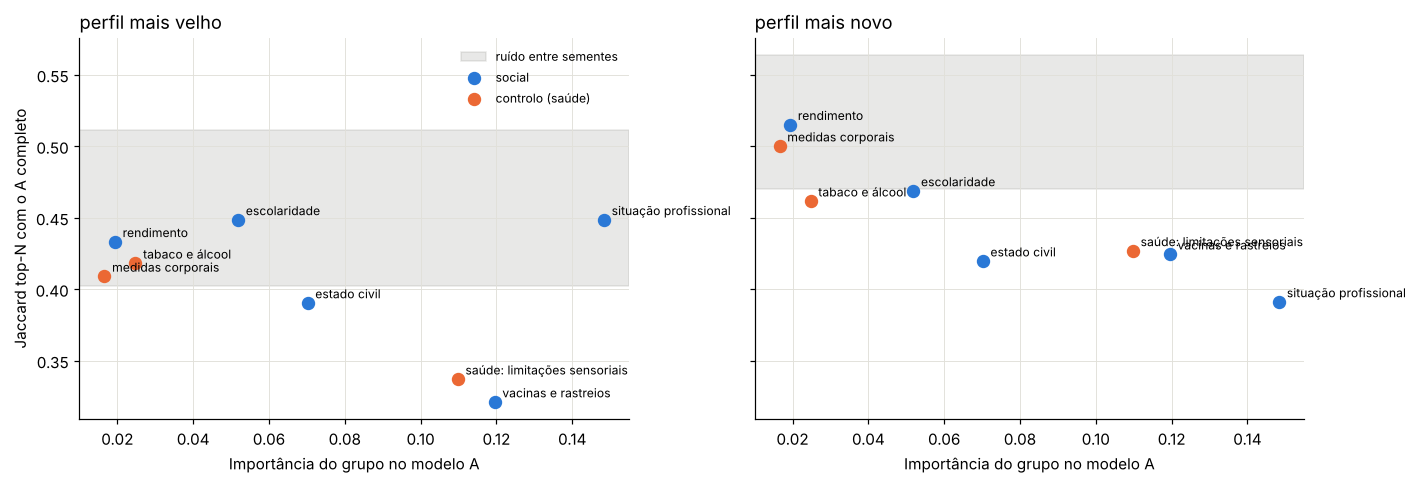


Caso PID 12797 nos dois modelos:


,modelo,real,idade_real_anos,idade_esperada_anos,dp_anos,desvio_ajustado,tipo,frac_sementes,MAINSTAT,MARSTALEGAL,HATLEVEL,HS1,n_doencas_cronicas
2955,A,13,77.0,26.46,5.37,-47.50,perfil mais novo,1.0,Tem um emprego ou trabalho (in,Solteiro,Secundário,Muito bom,1
2955,B,13,77.0,30.83,7.70,-38.46,perfil mais novo,1.0,Tem um emprego ou trabalho (in,Solteiro,Secundário,Muito bom,1


In [20]:
jac = lambda s0, s1: len(s0 & s1) / max(len(s0 | s1), 1)


def top_n(p, n_by_type, mcy=0):
    """Os N casos mais extremos por z em cada direção (com o filtro de incerteza): tamanho fixo."""
    d = discrepancies(p, mcy)
    d = d[d.dp_anos <= 12.5]
    old = d.sort_values("z", ascending=False).head(n_by_type["perfil mais velho"])
    yng = d[d.real >= mcy].sort_values("z").head(n_by_type["perfil mais novo"])
    return {"perfil mais velho": set(old.PID), "perfil mais novo": set(yng.PID)}


# (a) estabilidade
LA = [lists(p) for p in pA_s]
final = lists(pA)
stab = []
for t in TIPOS:
    j_ind = [jac(LA[i][t], LA[k][t]) for i in range(len(LA)) for k in range(i + 1, len(LA))]
    loo = [jac(final[t], lists(np.mean([p for k, p in enumerate(pA_s) if k != i], 0))[t]) for i in range(len(pA_s))] \
        if len(pA_s) > 2 else []
    fr = fracA.loc[list(final[t]), t] if final[t] else pd.Series(dtype=float)
    stab.append({"tipo": t, "n lista final": len(final[t]),
                 "n por semente (média)": np.mean([len(L[t]) for L in LA]),
                 "Jaccard entre sementes isoladas": np.mean(j_ind) if j_ind else np.nan,
                 "Jaccard final vs média sem 1 semente": np.mean(loo) if loo else np.nan,
                 "% da lista final marcada em todas as sementes": (fr == 1).mean() * 100 if len(fr) else np.nan,
                 "% marcada em ≥ 60% das sementes": (fr >= 0.6).mean() * 100 if len(fr) else np.nan})
print("Estabilidade das listas do modelo A:")
display(pd.DataFrame(stab).set_index("tipo").round(3))
# a rotatividade concentra-se perto do limiar?
dA = discrepancies(pA)
for t in TIPOS:
    f = fracA[t].values
    inst, est = (f > 0) & (f < 1), f == 1
    if inst.any() and est.any():
        print(f"{t}: |desvio ajustado| mediano (lista média) — marcados em todas as sementes "
              f"{np.median(np.abs(dA.desvio_ajustado[est])):.1f} anos | marcados só em algumas "
              f"{np.median(np.abs(dA.desvio_ajustado[inst])):.1f} anos (limiar: 15)")

# (b) ablação social com listas de tamanho fixo e 3 sementes
abl = []
if RUN_SOCIAL_ABLATION:
    N_TOP = {t: max(len(final[t]), 1) for t in TIPOS}
    TA = [top_n(p, N_TOP) for p in pA_s]
    ruido = {t: [jac(TA[i][t], TA[k][t]) for i in range(len(TA)) for k in range(i + 1, len(TA))] for t in TIPOS}
    # (c) controlos não sociais: importância de cada grupo medida no próprio modelo A (semente 0)
    famA = lambda rx: [b for b in BASES_ALL if re.match(rx, b)]
    HEALTH_GROUPS = {"tabaco e álcool (SK, AL)": famA(r"^(SK|AL)\d"),
                     "medidas corporais (BM, IMC)": famA(r"^BM\d") + ["IMC"],
                     "doenças crónicas (CD)": famA(r"^CD"),
                     "saúde autoavaliada (HS)": famA(r"^HS\d"),
                     "limitações sensoriais e físicas (PL)": famA(r"^PL\d"),
                     "consultas, internamentos, medicamentos (AM, HO, MD)": famA(r"^(AM|HO|MD)"),
                     "saúde mental (MH)": famA(r"^MH\d"),
                     "atividade física (PE)": famA(r"^PE\d"),
                     "dor (PN)": famA(r"^PN\d"),
                     "alimentação (DH)": famA(r"^DH\d"),
                     "acidentes (AC)": famA(r"^AC")}
    impA = permutation_importance(profA, X_all, y_all, {**SOCIAL, **HEALTH_GROUPS})
    target = impA.loc["vacinas e rastreios (PA*)", "aumento_perda"]
    fixed_ctrl = ["tabaco e álcool (SK, AL)", "medidas corporais (BM, IMC)"]
    pool = [g for g in impA.loc[list(HEALTH_GROUPS)].sort_values("aumento_perda", ascending=False).index
            if g not in fixed_ctrl]
    cands = [([g], impA.loc[g, "aumento_perda"]) for g in pool]          # grupos isolados
    combo = []
    for g in pool:                                                       # junções sucessivas (greedy)
        combo = combo + [g]
        if len(combo) > 1:
            cols_c = sum((HEALTH_GROUPS[x] for x in combo), [])
            cands.append((list(combo), permutation_importance(profA, X_all, y_all, {"c": cols_c}).aumento_perda.iloc[0]))
            if cands[-1][1] >= target:
                break
    best, imp_best = min(cands, key=lambda c: abs(c[1] - target))
    combo_name = "saúde: " + " + ".join(g.split(" (")[0] for g in best) + " (≈ importância de PA*)"
    CONTROLS = {g: HEALTH_GROUPS[g] for g in fixed_ctrl}
    CONTROLS[combo_name] = sum((HEALTH_GROUPS[g] for g in best), [])
    imp_ctrl = {**{g: impA.loc[g, "aumento_perda"] for g in fixed_ctrl}, combo_name: imp_best}
    print("Importância dos grupos no modelo A (aumento da perda ao baralhar o grupo):")
    display(impA.assign(tipo=["social" if g in SOCIAL else "saúde" for g in impA.index]).round(4))
    print(f"Controlo combinado escolhido: {combo_name} | importância {imp_best:.4f} (alvo PA*: {target:.4f})")

    ALL_ABL = {**{g: ("social", c) for g, c in SOCIAL.items()}, **{g: ("controlo (saúde)", c) for g, c in CONTROLS.items()}}
    for nome, (tipo_g, cols_s) in ALL_ABL.items():
        runs_s = run_seeds(lambda idx, c=cols_s: excl_A(idx, c), f"A sem {nome[:30]}", N_SEEDS_ABL, offset=10)
        ps = [to_probs(r["oof"]) for r in runs_s]
        TS = [top_n(p, N_TOP) for p in ps]
        row = {"grupo retirado": nome, "tipo": tipo_g,
               "importância no modelo A": impA.loc[nome, "aumento_perda"] if nome in impA.index else imp_ctrl[nome],
               "F1 OOF (média)": np.mean([f1_score(y_all, predict(p), average="macro") for p in ps])}
        for t in TIPOS:
            js = [jac(a[t], b[t]) for a in TS for b in TA]
            row[f"{t}: Jaccard top-N"] = np.mean(js)
            row[f"{t}: abaixo de todo o ruído"] = bool(ruido[t]) and np.mean(js) < min(ruido[t])
            row[f"{t}: n com limiar (média)"] = np.mean([len(lists(p)[t]) for p in ps])
        abl.append(row)
    abl = pd.DataFrame(abl).set_index("grupo retirado")
    for t in TIPOS:
        if ruido[t]:
            print(f"Ruído entre sementes do A completo ({t}, top-{N_TOP[t]}): Jaccard médio {np.mean(ruido[t]):.3f} "
                  f"(mín {min(ruido[t]):.3f}, máx {max(ruido[t]):.3f}, {len(ruido[t])} pares) | "
                  f"n com limiar por semente: {np.mean([len(L[t]) for L in LA]):.1f}")
    display(abl.round(3))

    fig, axs = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
    for ax, t in zip(axs, TIPOS):
        ax.axhspan(min(ruido[t]), max(ruido[t]), color=CINZA, alpha=0.15, label="ruído entre sementes")
        for tipo_g, cor in [("social", AZUL), ("controlo (saúde)", LARANJA)]:
            g = abl[abl.tipo == tipo_g]
            ax.scatter(g["importância no modelo A"], g[f"{t}: Jaccard top-N"], s=60, color=cor, label=tipo_g, zorder=3)
            for nome, r in g.iterrows():
                ax.annotate(nome.split(" (")[0][:28], (r["importância no modelo A"], r[f"{t}: Jaccard top-N"]),
                            xytext=(5, 3), textcoords="offset points", fontsize=8)
        ax.set_xlabel("Importância do grupo no modelo A"); ax.set_title(t, loc="left")
    axs[0].set_ylabel("Jaccard top-N com o A completo"); axs[0].legend(frameon=False, fontsize=8)
    plt.tight_layout(); plt.show()

caso = 12797
if caso in set(anA.PID):
    print(f"\nCaso PID {caso} nos dois modelos:")
    display(pd.concat([anA[anA.PID == caso].assign(modelo="A"), anB[anB.PID == caso].assign(modelo="B")])
            [["modelo", "real", "idade_real_anos", "idade_esperada_anos", "dp_anos", "desvio_ajustado", "tipo",
              "frac_sementes", "MAINSTAT", "MARSTALEGAL", "HATLEVEL", "HS1", "n_doencas_cronicas"]].round(2))

**Leitura (12.1–12.2).**
- **Desvio em anos e regra dos 40+.** Com o desvio em anos e o limiar de 15 anos, as faixas estreitas deixam de
  gerar falsos "mais novos". No modelo B, a regra dos 40+ retira 37 "mais novos" das faixas 30–39 (378 → 341).
  Acima dos 40 continua a haver um efeito de chão parcial: um "perfil de saúde mais novo" no modelo B significa
  sobretudo **sem problemas de saúde detetáveis para a idade**, e a idade estimada (por vezes ~18–20 anos) é o
  limite inferior do modelo, não uma "idade biológica".
- **Estabilidade.** Entre sementes isoladas do modelo A o Jaccard é ≈ 0.55. A lista final (média de 5 sementes)
  é muito mais estável: Jaccard 0.91 ("mais velhos") e 0.88 ("mais novos") face às médias que deixam uma semente
  de fora (valor otimista, porque as médias partilham 4 sementes). 56% das pessoas da lista final são marcadas em
  **todas** as sementes e 87–93% em pelo menos 60% delas. A rotatividade concentra-se **junto ao limiar**: o
  |desvio ajustado| mediano é ~19 anos nos casos marcados em todas as sementes e ~15 anos (o próprio limiar) nos
  marcados só em algumas. Por isso o ficheiro exportado inclui, para cada pessoa, a **fração de sementes** em que
  é marcada, que é mais informativa do que uma etiqueta binária.
- **Sobreposição A vs B.** 37% dos "mais velhos" e 42% dos "mais novos" do A também aparecem no B (Jaccard 0.10 e
  0.09) — bem abaixo da estabilidade do próprio A. A diferença entre modelos não é, portanto, só ruído de treino;
  mas também reflete o modelo B ser mais fraco (F1 0.23, QWK 0.80), por isso **não** permite, sozinha, concluir
  quanto das discrepâncias do A é social.
- **Ablação com controlos (listas de tamanho fixo, 3 sementes por ablação).** O ruído entre sementes do A
  completo é um Jaccard de 0.40–0.51 ("mais velhos", top-68) e 0.47–0.56 ("mais novos", top-86). As importâncias
  foram medidas no **próprio modelo A**. O controlo combinado junta 7 grupos de saúde (limitações, saúde mental,
  doenças crónicas, atividade física, alimentação, consultas/internamentos/medicamentos e saúde autoavaliada) e tem
  importância 0.110, perto da das vacinas e rastreios (0.120).

  | Grupo retirado | tipo | importância no A | "mais velhos" | "mais novos" |
  |---|---|---|---|---|
  | situação profissional | social | 0.148 | 0.45 — dentro do ruído | **0.39 — abaixo** |
  | vacinas e rastreios (PA\*) | social | 0.120 | **0.32 — abaixo** | **0.43 — abaixo** |
  | junção de 7 grupos de saúde | controlo | 0.110 | **0.34 — abaixo** | **0.43 — abaixo** |
  | estado civil | social | 0.070 | **0.39 — abaixo** | **0.42 — abaixo** |
  | escolaridade | social | 0.052 | 0.45 — dentro do ruído | **0.47 — no limite** |
  | tabaco e álcool | controlo | 0.025 | 0.42 — dentro do ruído | **0.46 — abaixo** |
  | rendimento | social | 0.019 | 0.43 — dentro do ruído | 0.52 — dentro do ruído |
  | medidas corporais | controlo | 0.017 | 0.41 — dentro do ruído | 0.50 — dentro do ruído |

  Pelo critério definido (se o controlo ficar dentro do ruído, o efeito é específico dos marcadores sociais; se
  cair como o das vacinas e rastreios, é só o efeito de retirar informação), o resultado é claro: **o controlo de
  saúde cai praticamente como as vacinas e rastreios** (0.34 vs 0.32 nos "mais velhos"; 0.43 vs 0.43 nos "mais
  novos"). Logo, a queda das vacinas e rastreios **não** mostra um efeito específico: é o que acontece ao retirar
  qualquer bloco de informação com esse peso.
- **O que o gráfico mostra.** O Jaccard desce, de forma aproximadamente contínua, com a importância do grupo
  retirado, e os pontos sociais e de controlo seguem a **mesma tendência**. Nos "mais novos", até o tabaco e
  álcool (importância 0.025) fica abaixo do ruído (0.46 vs mín. 0.47), por isso "abaixo do ruído" nesse perfil
  não basta como indício de efeito social. A única exceção à tendência é a **situação profissional nos "mais
  velhos"**: é o grupo mais importante e, mesmo assim, a lista quase não muda — retirá-la afeta a precisão geral
  do modelo, mas não quem é marcado como "mais velho". Nos "mais novos" a situação profissional dá a lista mais
  diferente (0.39), mas também é o grupo mais importante, e não há um controlo com importância ~0.15 para
  comparar, por isso este valor também não separa efeito social de perda de informação.
- **Limites do controlo.** Há só um controlo com importância próxima da de PA\* e nenhum perto da situação
  profissional (0.15) ou do estado civil (0.07); o controlo combinado retira muitas mais colunas do que PA\*; e a
  importância por permutação mede o efeito na perda global, não nas listas de discrepâncias. Com 3 sementes por
  ablação, diferenças de ±0.03 no Jaccard estão dentro da incerteza.
- **Situação profissional dos discrepantes.** Os reformados antecipados **não** se concentram nos "mais velhos"
  que só o A encontra (28% "só A" vs 40% "A e B"); os desempregados sim (16% vs 8%).
- **Conclusão.** A ablação **não** fornece evidência de que as discrepâncias do modelo A tenham uma origem
  especificamente social ou de política de saúde: retirar marcadores sociais muda as listas na medida em que
  retira informação, tal como retirar grupos de saúde com peso parecido. As listas devem, por isso, ser lidas
  como **perfis atípicos para a idade no conjunto de todas as variáveis**, sem atribuir a causa a um grupo
  concreto. Para o relatório, a afirmação defensável é a negativa: os marcadores sociais pesam no modelo A, mas
  não mudam as listas mais do que os grupos de saúde de peso semelhante.
- **Caso PID 12797** (75–79 anos, empregada, saúde "muito boa", 1 doença crónica, IMC 20.5): marcada em todas as
  sementes dos dois modelos, que estimam **entre os 25 e os 30 anos** (26.5 no A e 30.8 no B). Um desvio de ~50
  anos é mais compatível com um erro de preenchimento da idade ou com um caso excecional do que com uma "idade
  biológica" de ~27 anos — é um **candidato a verificar**.

### 12.3 Casos mais fortes do modelo B (saúde e hábitos)
Ordenados pelo desvio relativo à incerteza. São os candidatos mais claros a perfil de saúde atípico para a
idade — mesmo assim, a verificar caso a caso (podem ser erros de preenchimento).

In [21]:
def nota(r):
    n = []
    if abs(r.desvio_ajustado) >= 40:
        n.append("desvio extremo (≥ 40 anos): verificar dados")
    if r.dp_anos > 11:
        n.append("incerteza perto do limite (dp > 11)")
    return "; ".join(n)


anB["nota"] = anB.apply(nota, axis=1); anA["nota"] = anA.apply(nota, axis=1)
cols = ["PID", "real", "idade_real_anos", "idade_esperada_anos", "dp_anos", "desvio_ajustado", "z", "frac_sementes",
        "SEX", "MAINSTAT", "HS1", "HS3", "IMC", "n_doencas_cronicas", "nota"]
print("Perfil de saúde mais velho do que a idade declarada:")
display(anB[anB.tipo == "perfil mais velho"].sort_values("z", ascending=False)[cols].head(10).round(1))
print("Perfil de saúde mais novo do que a idade declarada (só 40+ anos):")
display(anB[anB.tipo == "perfil mais novo"].sort_values("z")[cols].head(10).round(1))
yb = anB[anB.tipo == "perfil mais novo"]
healthy = (anB.n_doencas_cronicas == 0) & (anB.HS1.isin(["Bom", "Muito bom"]))
print(f"'Mais novos' do modelo B com idade esperada < 25 anos (chão do modelo): {np.mean(yb.idade_esperada_anos < 25):.0%}")
print(f"Idade esperada pelo modelo B para pessoas sem doenças crónicas e com saúde boa/muito boa, por faixa real:")
print(anB[healthy].groupby("real").idade_esperada_anos.mean().round(1).to_frame().T.to_string())

caso = 3024
if caso in set(anB.PID):
    r = train[train.PID == caso].iloc[0]
    print(f"\nCaso PID {caso} (modelo B): faixa real {MID[int(r[TARGET])]:.0f} anos, idade esperada "
          f"{anB.loc[anB.PID == caso, 'idade_esperada_anos'].iloc[0]:.0f}, dp {anB.loc[anB.PID == caso, 'dp_anos'].iloc[0]:.1f}")
    print(r[["SEX", "MAINSTAT", "HATLEVEL", "HS1", "HS2", "HS3", "PL6", "MD1", "PN1"]].to_string())
    print("doenças crónicas declaradas:", [c for c in train.columns if c.startswith("CD1") and r[c] == "Sim"])
out = anA[["PID", "real", "idade_real_anos"]].copy()
for nome, d in [("A", anA), ("B", anB)]:
    for c in ["idade_esperada_anos", "dp_anos", "desvio_ajustado", "z", "tipo", "nota"]:
        out[f"{c}_{nome}"] = d[c].values
for nome, fr in [("A", fracA), ("B", fracB)]:
    out[f"frac_sementes_mais_velho_{nome}"] = fr["perfil mais velho"].values
    out[f"frac_sementes_mais_novo_{nome}"] = fr["perfil mais novo"].values
out = pd.concat([out, info_cols], axis=1)
out.to_csv(f"{OUT_DIR}/discrepancias_perfil_mlp_corn.csv", index=False)
print("Lista completa (modelos A e B): discrepancias_perfil_mlp_corn.csv "
      "(inclui, para cada pessoa, a fração de sementes em que é marcada em cada direção)")

Perfil de saúde mais velho do que a idade declarada:

,PID,real,idade_real_anos,idade_esperada_anos,dp_anos,desvio_ajustado,z,frac_sementes,SEX,MAINSTAT,HS1,HS3,IMC,n_doencas_cronicas,nota
8879,4106.0,10,62.0,86.6,4.1,26.5,6.5,1.0,Homem,Incapacitado permanente para o,Muito mau,Severamente limitado,NaN,1,
1383,3024.0,0,16.0,81.8,12.4,57.6,4.7,0.6,Homem,Outra situação de inatividade,Bom,Severamente limitado,23.1,2,desvio extremo (≥ 40 anos): verificar dados; i...
4682,6974.0,12,72.0,85.8,5.2,18.9,3.7,1.0,Homem,"Reformado, com reforma antecip",Bom,Limitado mas não severame,NaN,5,
9444,3214.0,5,37.0,74.4,10.1,35.6,3.5,1.0,Mulher,Incapacitado permanente para o,Mau,Limitado mas não severame,24.2,5,
5633,3375.0,7,47.0,78.7,10.5,33.5,3.2,1.0,Homem,Incapacitado permanente para o,Mau,Limitado mas não severame,24.3,3,
3835,10448.0,12,72.0,85.5,6.0,18.6,3.1,1.0,Homem,Incapacitado permanente para o,Muito mau,Severamente limitado,23.9,3,
920,3556.0,10,62.0,84.0,8.0,23.9,3.0,1.0,Mulher,"Reformado, com reforma antecip",Muito mau,Severamente limitado,21.9,3,
8602,5614.0,13,77.0,85.1,5.4,15.8,2.9,1.0,Mulher,Ocupa-se de tarefas domésticas,Muito mau,Nada limitado,22.2,7,
10689,5689.0,8,52.0,81.9,10.8,31.1,2.9,1.0,Homem,"Reformado, com reforma antecip",Muito mau,Severamente limitado,NaN,4,
268,9711.0,4,32.0,64.0,9.8,27.8,2.8,1.0,Homem,Tem um emprego ou trabalho (in,Mau,Nada limitado,30.5,3,


Perfil de saúde mais novo do que a idade declarada (só 40+ anos):


,PID,real,idade_real_anos,idade_esperada_anos,dp_anos,desvio_ajustado,z,frac_sementes,SEX,MAINSTAT,HS1,HS3,IMC,n_doencas_cronicas,nota
647,4403.0,7,47.0,18.2,3.6,-27.0,-7.6,1.0,Mulher,Tem um emprego ou trabalho (in,Bom,Nada limitado,21.2,2,
7932,12451.0,8,52.0,19.6,5.2,-31.1,-6.0,1.0,Mulher,Outra situação de inatividade,Muito bom,Nada limitado,20.9,3,
3993,13612.0,7,47.0,19.3,4.5,-25.9,-5.8,1.0,Mulher,Tem um emprego ou trabalho (in,Muito bom,Nada limitado,21.3,0,
7265,4893.0,6,42.0,18.9,4.0,-22.6,-5.7,1.0,Homem,Tem um emprego ou trabalho (in,Muito bom,Nada limitado,26.5,0,
9059,11060.0,8,52.0,19.7,5.7,-31.1,-5.5,1.0,Mulher,Desempregado,Muito bom,Nada limitado,23.4,0,
16,6175.0,7,47.0,19.0,4.8,-26.2,-5.5,1.0,Mulher,Tem um emprego ou trabalho (in,Muito bom,Nada limitado,18.6,0,
8657,1899.0,7,47.0,18.9,4.9,-26.3,-5.4,1.0,Mulher,Tem um emprego ou trabalho (in,Bom,Nada limitado,18.7,0,
8720,11162.0,6,42.0,19.3,4.2,-22.3,-5.3,1.0,Mulher,Ocupa-se de tarefas domésticas,Muito bom,Nada limitado,28.4,0,
7560,7574.0,7,47.0,19.3,4.9,-25.9,-5.3,1.0,Mulher,Tem um emprego ou trabalho (in,Muito bom,Nada limitado,22.1,2,
901,7826.0,11,67.0,21.8,8.1,-41.5,-5.1,1.0,Mulher,"Reformado, com reforma antecip",Muito bom,Nada limitado,17.6,0,desvio extremo (≥ 40 anos): verificar dados


'Mais novos' do modelo B com idade esperada < 25 anos (chão do modelo): 16%
Idade esperada pelo modelo B para pessoas sem doenças crónicas e com saúde boa/muito boa, por faixa real:
real                   0     1     2     3     4     5     6     7     8     9     10    11    12    13    14    15
idade_esperada_anos  23.9  25.6  29.0  31.9  34.4  35.7  38.1  38.8  42.9  44.2  49.8  51.3  55.0  49.1  55.3  61.6

Caso PID 3024 (modelo B): faixa real 16 anos, idade esperada 82, dp 12.4
SEX                                 Homem
MAINSTAT    Outra situação de inatividade
HATLEVEL          Nenhum nível completado
HS1                                   Bom
HS2                                   Sim
HS3                  Severamente limitado
PL6                  Não consegue de todo
MD1                                   Sim
PN1                               Nenhuma
doenças crónicas declaradas: ['CD1M', 'CD1N']


Lista completa (modelos A e B): discrepancias_perfil_mlp_corn.csv (inclui, para cada pessoa, a fração de sementes em que é marcada em cada direção)


**Leitura (12.3).**
- Os "mais velhos" mais fortes do modelo B são sobretudo pessoas **incapacitadas para o trabalho** ou com
  **reforma antecipada**, com saúde má ou muito má e limitação severa — perfis de saúde de facto típicos de idades
  mais altas.
- Os "mais novos" mais fortes são pessoas de 40–55 anos (e alguns mais velhos) com saúde boa ou muito boa, sem
  limitações e com IMC baixo-normal. A idade estimada (~18–20 anos) é o **chão** do modelo de saúde: o que se pode
  dizer é que não têm problemas de saúde detetáveis para a idade, não que "parecem ter 19 anos".
- **Caso PID 3024 — a verificar.** Tem 15–17 anos e o modelo B estima ~82 anos, mas passa o filtro de incerteza
  mesmo no limite (`dp_anos` = 12.4 para um máximo de 12.5) e só é marcado em 60% das sementes; o modelo A não o
  marca (incerteza muito alta). Os dados mostram um jovem com **limitação severa**, uma atividade física que "não
  consegue de todo" fazer, duas doenças crónicas, medicação e "outra situação de inatividade", sem escolaridade
  completa. É provavelmente um **jovem com incapacidade grave**, não um perfil de envelhecimento: o modelo de saúde
  só sabe que limitações destas são típicas de idades altas. Pode também haver erro de dados. Casos assim ficam
  assinalados na coluna `nota` (desvio ≥ 40 anos ou incerteza perto do limite) e não devem ser apresentados como
  "idade biológica de 82 anos".

### 12.4 Perfil de saúde das discrepâncias — validação não circular
Comparar a saúde dos discrepantes com a dos pares é **circular** se o modelo que os selecionou usa essa mesma
variável: um modelo que estima a idade a partir das doenças crónicas escolhe, por construção, como "mais velhos"
pessoas com mais doenças do que os pares.

Para evitar isto usa-se **leave-group-out**: para cada variável analisada treina-se o modelo B **sem o grupo a
que ela pertence**, e só então se compara essa variável entre discrepantes e pares:

| Variável analisada | Modelo usado para selecionar as discrepâncias |
|---|---|
| saúde má/muito má, limitado nas atividades | B sem HS1–HS3 |
| nº de doenças crónicas | B sem CD\* |
| IMC | B sem BM1, BM2 e IMC |

Para cada discrepante calcula-se `valor − média dos "normais" da mesma faixa real`; a média dessas diferenças tem
**IC 95% bootstrap** (2000 reamostragens das pessoas). Mostra-se também a versão circular (modelo B completo).
As duas versões usam a média de 3 sementes, para a comparação ser justa.
**Atenção:** as duas versões selecionam **pessoas diferentes** (o `n` muda), por isso a comparação entre colunas
não é entre as mesmas pessoas.

In [22]:
CHECKS = {"HS": (["HS1", "HS2", "HS3"], {"saude_ma": "saúde má/muito má", "limitado": "limitado nas atividades"}),
          "CD": ([c for c in BASES_ALL if c.startswith("CD")], {"n_doencas_cronicas": "nº doenças crónicas"}),
          "BM": (["BM1", "BM2", "IMC"], {"IMC": "IMC"})}


def peer_diffs(d, var, tipo):
    peers = d[d.tipo == "normal"].groupby("real")[var].mean()
    g = d[d.tipo == tipo]
    return (g[var] - peers.loc[g.real].values).dropna().values


def boot_ci(x, n=2000, seed=SEED):
    if len(x) < 2:
        return np.nan, np.nan
    r = np.random.default_rng(seed)
    m = [r.choice(x, len(x)).mean() for _ in range(n)]
    return np.percentile(m, [2.5, 97.5])


rows = []
# versão circular com o mesmo nº de sementes que a não circular (comparação justa)
anB_valid = pd.concat([discrepancies(np.mean(pB_s[:N_SEEDS_VALID], 0), MIN_CLASS_YOUNGER_B), info_cols], axis=1)
if RUN_HEALTH_VALIDATION:
    for grp_, (cols_g, vars_g) in CHECKS.items():
        runs_g = run_seeds(lambda idx, c=cols_g: excl_B(idx, c), f"B sem {grp_}", N_SEEDS_VALID)
        p_g = np.mean([to_probs(r["oof"]) for r in runs_g], 0)
        d_g = pd.concat([discrepancies(p_g, MIN_CLASS_YOUNGER_B), info_cols], axis=1)
        for v, lab in vars_g.items():
            for t in ["perfil mais velho", "perfil mais novo"]:
                x = peer_diffs(d_g, v, t); lo_, hi_ = boot_ci(x)
                xc = peer_diffs(anB_valid, v, t)
                rows.append({"variável": lab, "grupo": t, "n (não circular)": len(x),
                             "diferença vs pares": x.mean() if len(x) else np.nan, "IC 95% inf": lo_, "IC 95% sup": hi_,
                             "IC exclui 0": bool(lo_ > 0 or hi_ < 0),
                             "n (circular)": len(xc), "diferença circular (B completo)": xc.mean() if len(xc) else np.nan})
    val = pd.DataFrame(rows)
    display(val.round(3))

B sem HS s0 fold 0: F1 treino=0.3200 | F1 fold=0.2373 (9s)


B sem HS s0 fold 1: F1 treino=0.3128 | F1 fold=0.2178 (9s)


B sem HS s0 fold 2: F1 treino=0.3223 | F1 fold=0.2215 (9s)


B sem HS s0 fold 3: F1 treino=0.3307 | F1 fold=0.2313 (9s)


B sem HS s0 fold 4: F1 treino=0.3279 | F1 fold=0.2218 (9s)


B sem HS s1 fold 0: F1 treino=0.3115 | F1 fold=0.2225 (9s)


... (36 outputs left out)

B sem BM s2 fold 2: F1 treino=0.3132 | F1 fold=0.2224 (9s)


B sem BM s2 fold 3: F1 treino=0.3208 | F1 fold=0.2173 (8s)


B sem BM s2 fold 4: F1 treino=0.3198 | F1 fold=0.2165 (9s)


,variável,grupo,n (não circular),diferença vs pares,IC 95% inf,IC 95% sup,IC exclui 0,n (circular),diferença circular (B completo)
0,saúde má/muito má,perfil mais velho,224,0.194,0.136,0.254,True,227,0.219
1,saúde má/muito má,perfil mais novo,350,-0.098,-0.116,-0.079,True,340,-0.096
2,limitado nas atividades,perfil mais velho,223,0.322,0.261,0.380,True,226,0.337
3,limitado nas atividades,perfil mais novo,345,-0.179,-0.210,-0.145,True,336,-0.176
4,nº doenças crónicas,perfil mais velho,233,1.659,1.390,1.943,True,227,1.951
5,nº doenças crónicas,perfil mais novo,357,-1.447,-1.619,-1.264,True,342,-1.700
6,IMC,perfil mais velho,230,2.964,2.126,3.687,True,217,1.388
7,IMC,perfil mais novo,345,-1.551,-1.930,-1.174,True,331,-2.084


**Leitura (12.4).**
- **As diferenças sobrevivem à validação não circular.** Com discrepâncias selecionadas por um modelo que não
  usa a variável analisada, todos os IC 95% excluem o zero e mantêm o sinal esperado: os "mais velhos" têm mais
  saúde má (+19 p.p.), mais limitação nas atividades (+32 p.p.), mais doenças crónicas (+1.7) e IMC mais alto
  (+3.0) do que os pares da mesma faixa; os "mais novos", o contrário.
- **Comparação com a versão circular (as duas com 3 sementes):**
  - *doenças crónicas:* a diferença é **menor** sem circularidade nos dois grupos (+1.95 → +1.66; −1.70 → −1.45) —
    parte da diferença vinha da construção;
  - *saúde autoavaliada e limitação:* ligeiramente menor nos "mais velhos" (+22 → +19 p.p.; +34 → +32 p.p.) e
    **praticamente igual** nos "mais novos" (−9.6 vs −9.8 p.p.; −17.6 vs −17.9 p.p.);
  - *IMC:* **padrão misto** — maior sem circularidade nos "mais velhos" (+1.4 → +3.0) e menor nos "mais novos"
    (−2.1 → −1.6).
  Não se pode, por isso, dizer em geral que "parte do efeito vinha da construção": isso só se vê claramente nas
  doenças crónicas.
- **As duas versões não comparam as mesmas pessoas.** Cada versão seleciona o seu próprio conjunto de
  discrepantes (os `n` diferem, p. ex. 217 vs 230 "mais velhos" no IMC), por isso a diferença entre colunas mistura
  o efeito da circularidade com a troca de pessoas.
- **Limite.** Retirar um grupo não elimina variáveis correlacionadas com ele (sem as doenças crónicas, o modelo
  ainda usa medicamentos, consultas e limitações físicas). O resultado deve ser descrito como **consistente
  com** diferenças reais de saúde entre discrepantes e pares, não como prova independente.

## 13. Submissão (modelo de competição)

In [23]:
sub[TARGET] = predict(p_test)
assert len(sub) == len(test) and sub[TARGET].between(0, K - 1).all()
sub.to_csv(f"{OUT_DIR}/submission_mlp_corn_cv5.csv", index=False)
print(f"Regra: {RULE} | T por fold = {np.round(T_FOLDS, 3).tolist()} | F1 OOF (folds 42) = {ref['macroF1']:.4f} | "
      f"estimativa honesta = {F1_HONESTO:.4f}")
print("Submissão guardada em submission_mlp_corn_cv5.csv")
print(sub[TARGET].value_counts().sort_index().to_dict())

Regra: argmax | T por fold = [1.0, 1.0, 1.0, 1.0, 1.0] | F1 OOF (folds 42) = 0.4767 | estimativa honesta = 0.4746
Submissão guardada em submission_mlp_corn_cv5.csv
{0: 83, 1: 46, 2: 122, 3: 154, 4: 125, 5: 204, 6: 319, 7: 308, 8: 265, 9: 358, 10: 355, 11: 316, 12: 359, 13: 271, 14: 201, 15: 169}
